# Introduction and Data Loading.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
data = pd.read_csv("../SyntheticData_Training.csv")
data = data.iloc[:, 1:] # remove id column
target = data.columns[-1] # save target column

In [2]:
data[target].value_counts()

inhospital_mortality
0    2567
1     119
Name: count, dtype: int64

In [3]:
features = [feature for feature in data.columns.tolist() if not feature.startswith("admitabx")]
total_data = len(data)
print("Initial number of features is: ", len(features))
print("")
print("Removed columns\t\t\tMissing values perecentage")
for f in features:
    missing_value_percentage = data[f].isna().sum()/total_data
    if missing_value_percentage > 0.8:
        print(f"{f}\t\t\t {missing_value_percentage:.2%}")
        features.remove(f)
print("")
print("Remaining features is: ", len(features))

dictionary_of_features = {f:data[f].isna().sum()/total_data for f in features}
dictionary_of_features
dict(sorted(dictionary_of_features.items(), key=lambda item: item[1], reverse=True))


Initial number of features is:  118

Removed columns			Missing values perecentage
spo2other_adm			 93.26%
lactate2_mmolpl_adm			 82.54%
nonexclbreastfed_adm			 96.91%

Remaining features is:  115


{'vaccmeaslessource_adm': np.float64(0.35219657483246464),
 'lactate_mmolpl_adm': np.float64(0.1727475800446761),
 'hematocrit_gpdl_adm': np.float64(0.1701414743112435),
 'momagefirstpreg_adm': np.float64(0.08339538346984364),
 'sqi2_perc_oxi_adm': np.float64(0.077066269545793),
 'spo2site2_pc_oxi_adm': np.float64(0.0763216679076694),
 'vaccpneumocsource_adm': np.float64(0.06887565152643335),
 'vaccdptsource_adm': np.float64(0.05323901712583768),
 'sqi1_perc_oxi_adm': np.float64(0.04839910647803425),
 'hctpretransfusion_adm': np.float64(0.01600893521965748),
 'birthattend_adm': np.float64(0.011169024571854059),
 'momageknown_adm': np.float64(0.008190618019359643),
 'momage_adm': np.float64(0.007073715562174236),
 'height_cm_adm': np.float64(0.0052122114668652275),
 'muac_mm_adm': np.float64(0.004839910647803425),
 'weight_kg_adm': np.float64(0.0033507073715562173),
 'glucose_mmolpl_adm': np.float64(0.0033507073715562173),
 'momhiv_adm': np.float64(0.0022338049143708115),
 'rr_brpm_app_

**Observation**: There are still significant missing values. I will increase the criteria for unacceptable data.

In [4]:
features = [feature for feature in data.columns.tolist() if not feature.startswith("admitabx")]
total_data = len(data)
print("Initial number of features is: ", len(features))
print("")
print("Removed columns\t\t\tMissing values perecentage")
for f in features[:]:
    missing_value_percentage = data[f].isna().sum()/total_data
        
    if missing_value_percentage > 0.1:
        print(f"{f}\t\t\t {missing_value_percentage:.2%}")
        features.remove(f)
print("")
print("Remaining features is: ", len(features))

dictionary_of_features = {f:data[f].isna().sum()/total_data for f in features}
dictionary_of_features
dict(sorted(dictionary_of_features.items(), key=lambda item: item[1], reverse=True))


Initial number of features is:  118

Removed columns			Missing values perecentage
spo2other_adm			 93.26%
hematocrit_gpdl_adm			 17.01%
lactate_mmolpl_adm			 17.27%
lactate2_mmolpl_adm			 82.54%
vaccmeaslessource_adm			 35.22%
nonexclbreastfed_adm			 96.91%

Remaining features is:  112


{'momagefirstpreg_adm': np.float64(0.08339538346984364),
 'sqi2_perc_oxi_adm': np.float64(0.077066269545793),
 'spo2site2_pc_oxi_adm': np.float64(0.0763216679076694),
 'vaccpneumocsource_adm': np.float64(0.06887565152643335),
 'vaccdptsource_adm': np.float64(0.05323901712583768),
 'sqi1_perc_oxi_adm': np.float64(0.04839910647803425),
 'hctpretransfusion_adm': np.float64(0.01600893521965748),
 'birthattend_adm': np.float64(0.011169024571854059),
 'momageknown_adm': np.float64(0.008190618019359643),
 'momage_adm': np.float64(0.007073715562174236),
 'height_cm_adm': np.float64(0.0052122114668652275),
 'muac_mm_adm': np.float64(0.004839910647803425),
 'weight_kg_adm': np.float64(0.0033507073715562173),
 'glucose_mmolpl_adm': np.float64(0.0033507073715562173),
 'momhiv_adm': np.float64(0.0022338049143708115),
 'rr_brpm_app_adm': np.float64(0.0018615040953090098),
 'priorhosp_adm': np.float64(0.0018615040953090098),
 'hivstatus_adm': np.float64(0.0018615040953090098),
 'spo2site1_pc_oxi_adm'

In [5]:
# checking to see if any missing values are '0'
for f in features[:]:
    try:
        if data[f].describe()['min'] == 0.0:
            print(f)
    except:
        pass

alivechildren_adm
deadchildren_adm
glucose_mmolpl_adm
sqi1_perc_oxi_adm
sqi2_perc_oxi_adm
inhospital_mortality


In [6]:
# OK let's inspect the features now
for f in features:
    # print(f)
    pass

# Visualization

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set Seaborn style (optional)
sns.set_style("darkgrid")

# Identify numerical columns
numerical_columns = data[features].select_dtypes(include=["int64", "float64"]).columns

# Filter the data based on the target values
data_true = data[data[target] == True]
data_false = data[data[target] == False]

# Plot distribution of each numerical feature for both target=True and target=False
plt.figure(figsize=(14, len(numerical_columns) * 3))
for idx, feature in enumerate(numerical_columns, 1):
    plt.subplot(len(numerical_columns), 2, idx)
    
    # Plot KDE for target=True
    sns.kdeplot(data_true[feature], color='blue', label='target=True', fill=True)
    
    # Plot KDE for target=False
    sns.kdeplot(data_false[feature], color='red', label='target=False', fill=True)
    
    plt.title(f"{feature} | Skewness (True): {round(data_true[feature].skew(), 2)} | Skewness (False): {round(data_false[feature].skew(), 2)}")
    plt.legend()

# Adjust layout and show plots
plt.tight_layout()
plt.show()


AttributeError: 'Index' object has no attribute 'remove'

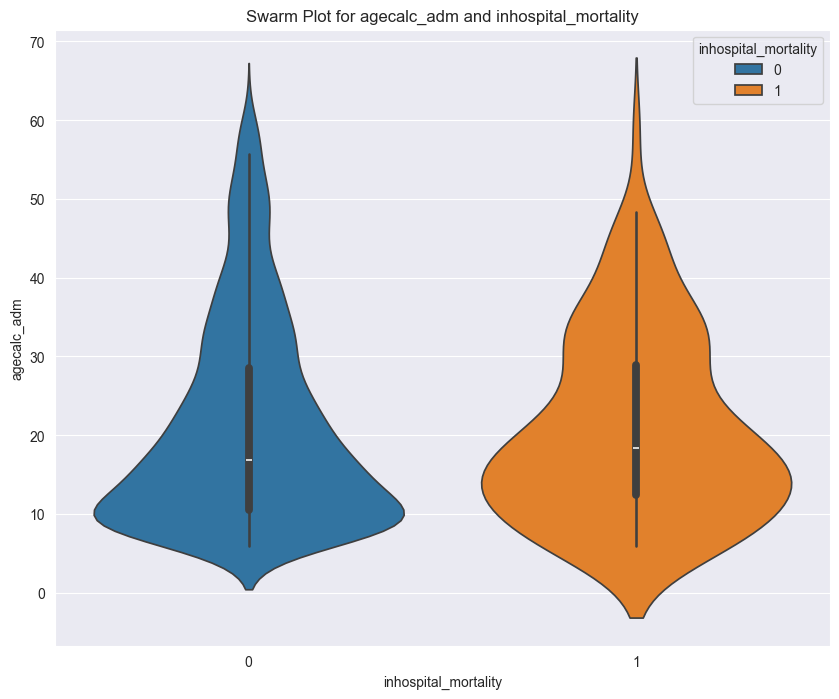

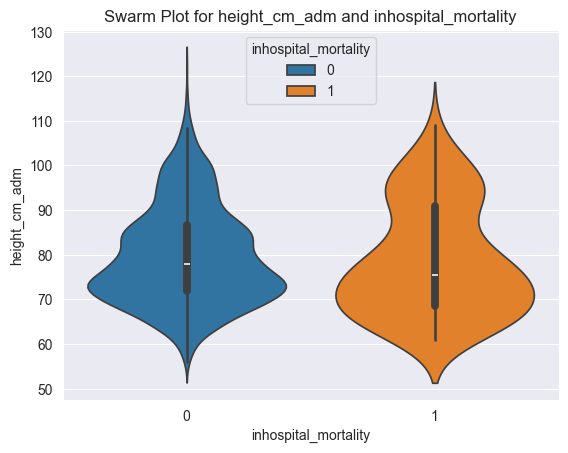

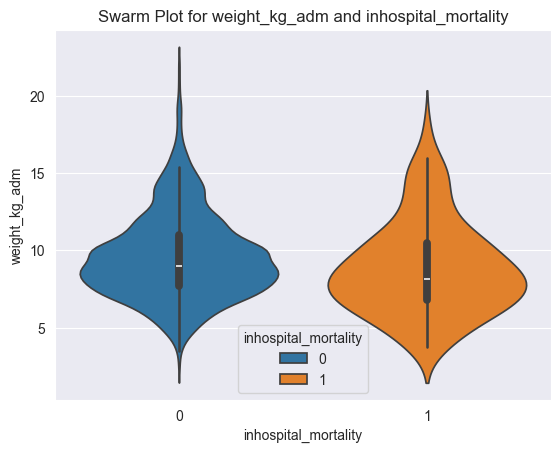

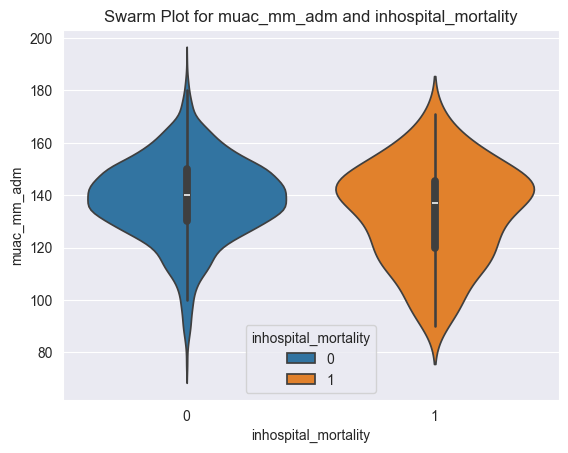

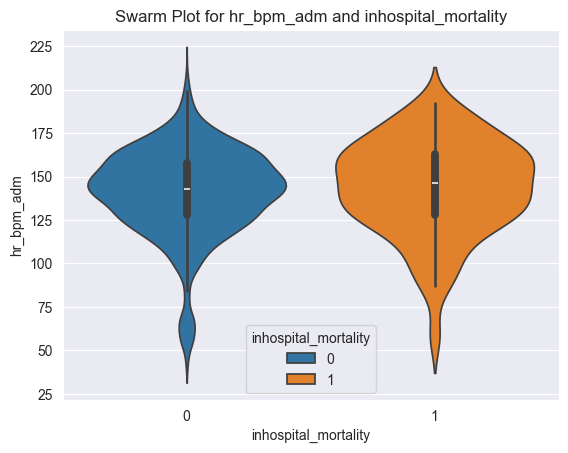

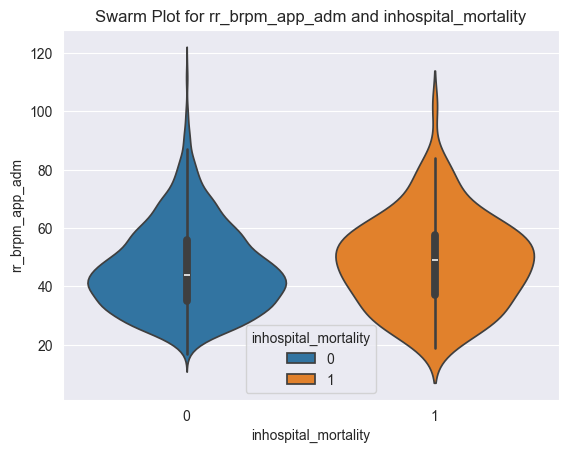

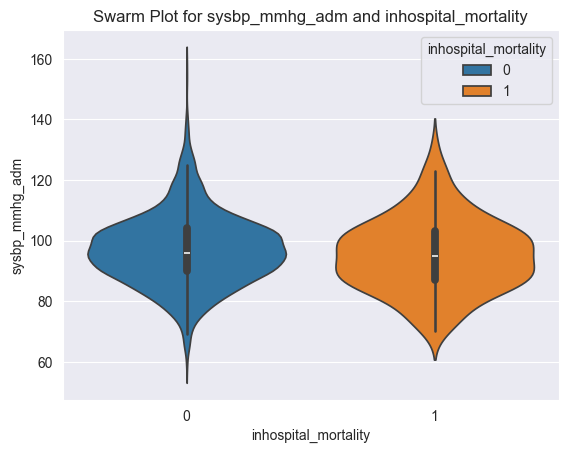

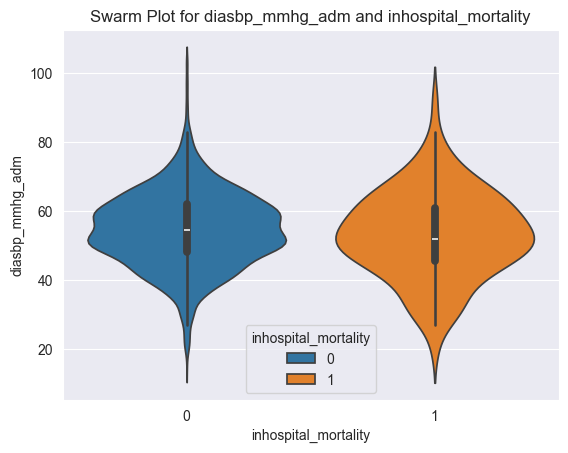

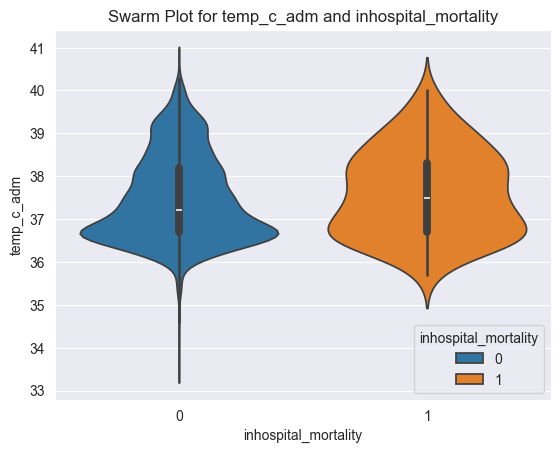

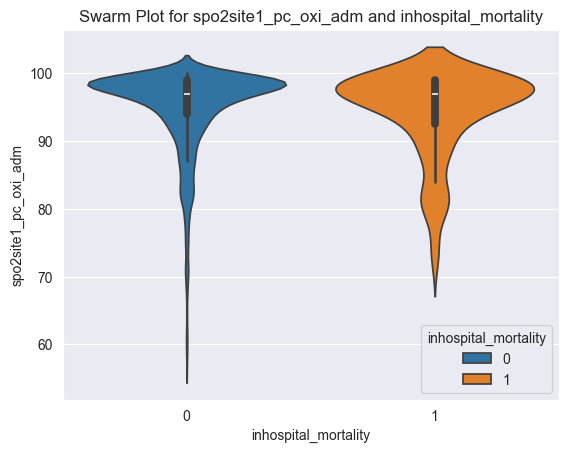

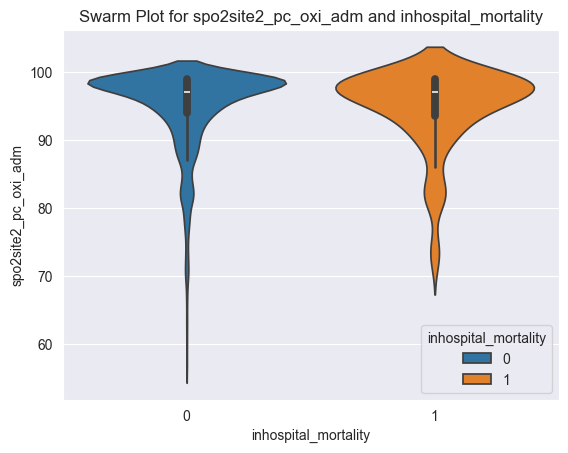

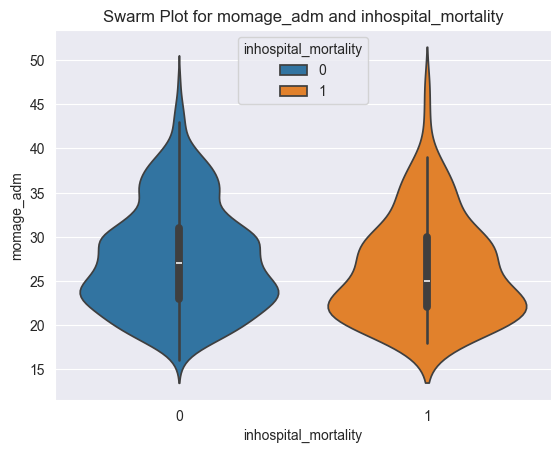

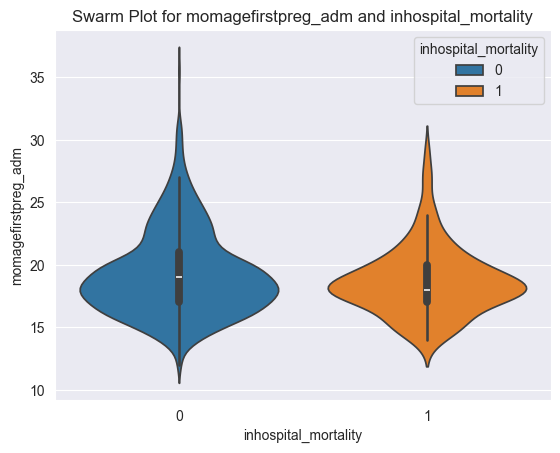

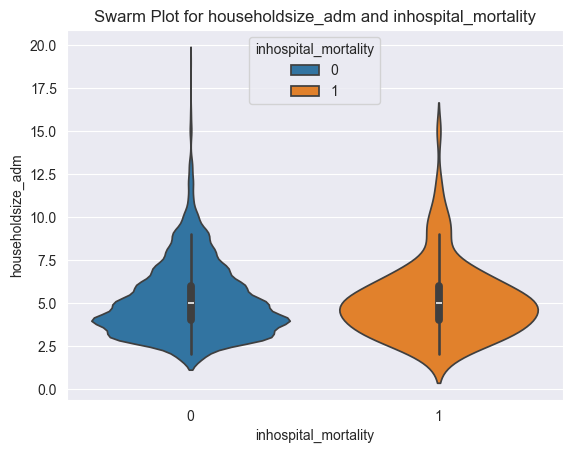

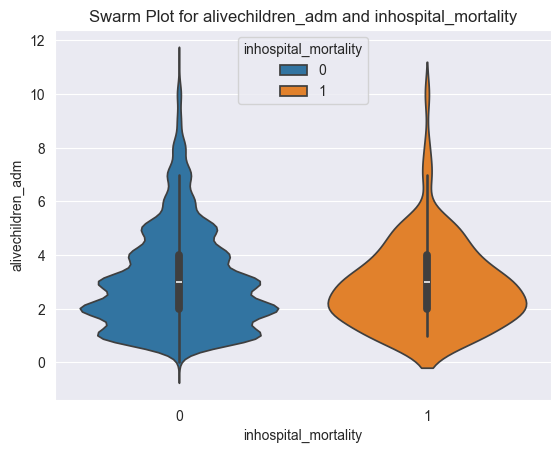

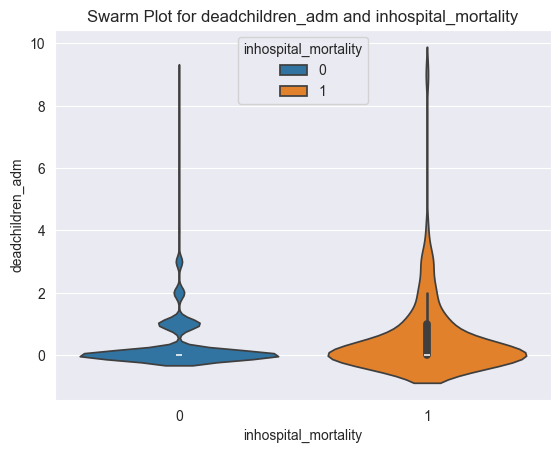

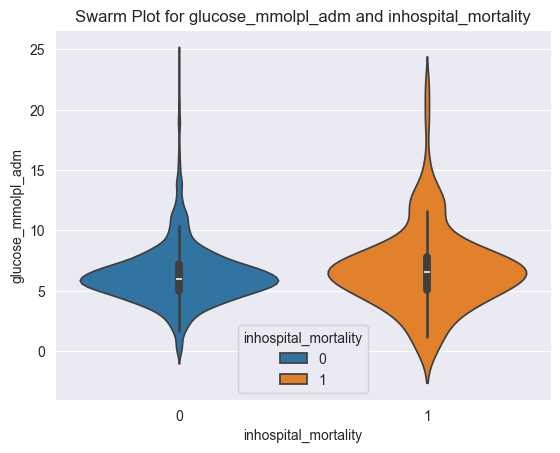

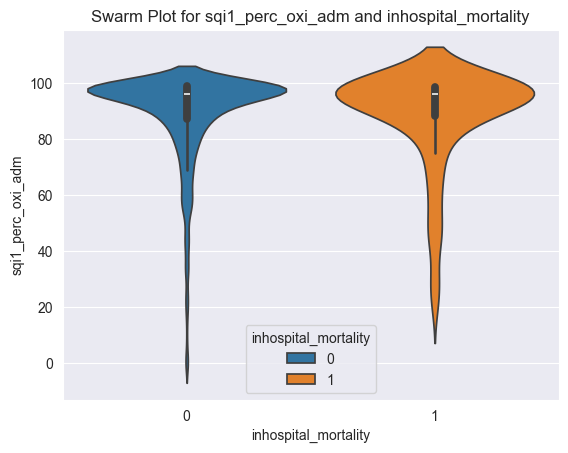

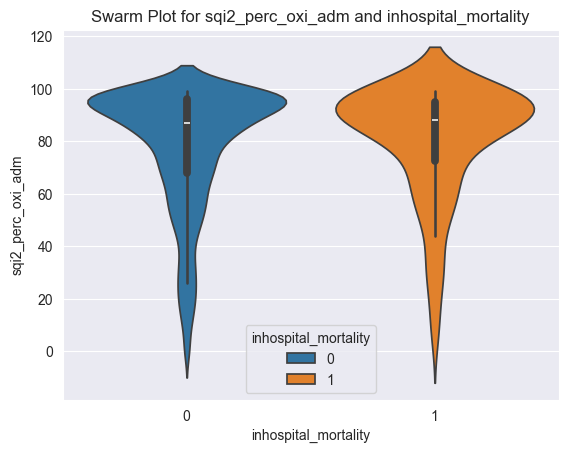

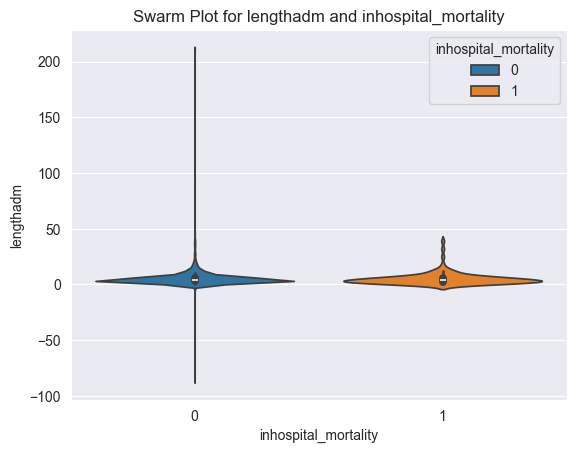

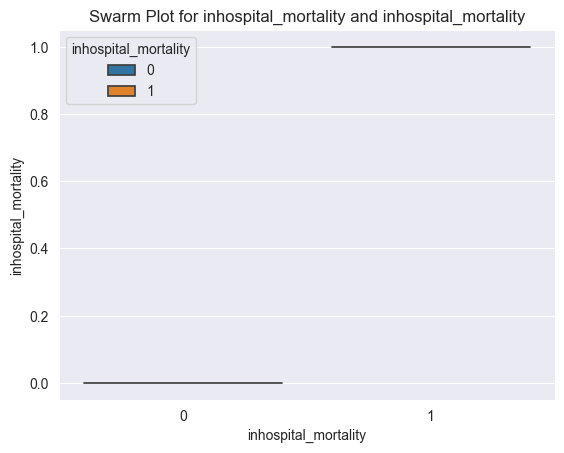

In [9]:
# swarm plot

# Assuming 'df' is your DataFrame
plt.figure(figsize=(10, 8))

# Using Seaborn to create a swarm plot
for f in numerical_columns:
    sns.violinplot(x=target, y=f, data=data, hue=target)

    plt.title(f'Swarm Plot for {f} and {target}')
    plt.xlabel(target)
    plt.ylabel(f)
    plt.show()

# Multivariate Analysis

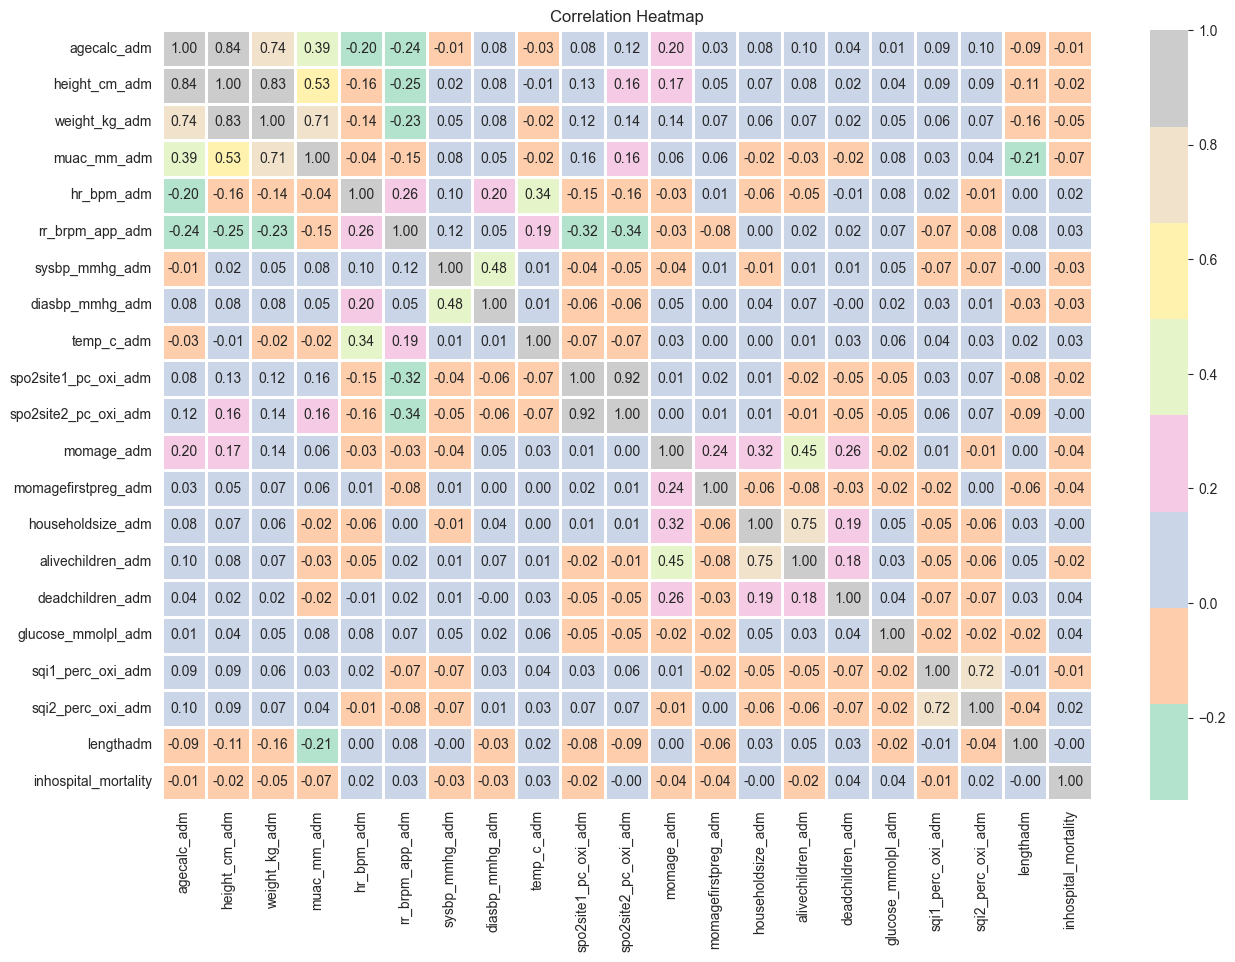

In [10]:
# Assuming 'df' is your DataFrame
plt.figure(figsize=(15, 10))

# Using Seaborn to create a heatmap
sns.heatmap(data[numerical_columns].corr(), annot=True, fmt='.2f', cmap='Pastel2', linewidths=2)

plt.title('Correlation Heatmap')
plt.show()

vaccmeaslessource

# Missing values strategy...


In [11]:
data_dictionary = pd.read_csv("../SyntheticData_DataDictionary_V1.csv")
data_dictionary[['Data Type', 'Variable Source']] = data_dictionary['Variable Type'].str.replace(r'[()]', '', regex=True).str.split('\n', expand=True)
data_dictionary.drop(columns=['Variable Type'], inplace=True)
data_dictionary

,Collection Type,Variable Name,Field Label,Missing Pattern,Details,Data Type,Variable Source
0,Admission,studyid_adm,Study ID,No missing values,NaN,Discrete,Patient details
1,Admission,agecalc_adm,Age at admission (in months),No missing values,NaN,Continuous,Patient details
2,Admission,sex_adm,Sex,No missing values,NaN,Categorical,Patient details
3,Admission,height_cm_adm,Height or length (in cm),14 missing values\n(0.5%),NaN,Continuous,Clinical
4,Admission,weight_kg_adm,Weight (in kg),9 missing values\n(0.3%),NaN,Continuous,Clinical
...,...,...,...,...,...,...,...
135,Admission,glucose_mmolpl_adm,Blood glucose (mmol/L),9 missing values\n(0.3%),NaN,Continuous,Laboratory
136,Admission,sqi1_perc_oxi_adm,Best admission SQI,130 missing values\n(4.8%),NaN,Continuous,Recording data
137,Admission,sqi2_perc_oxi_adm,2nd best admission SQI,207 missing values\n(7.7%),NaN,Continuous,Recording data
138,Outcome,lengthadm,Length of admission,No missing values,NaN,Discrete,Clinical


In [12]:
data_dictionary[data_dictionary.Details.notna()]

,Collection Type,Variable Name,Field Label,Missing Pattern,Details,Data Type,Variable Source
40,Intervention,admitabx_adm_20,What anti-infective(s) were given at admission...,No missing values,Indicates an antimicrobial was given that is n...,Categorical,Clinical
78,Admission,comorbidity_adm_10,Co-morbid diagnoses (check all that apply). No...,No missing values,Indicates comorbidity that is not one of the s...,Categorical,Clinical
88,Admission,nonexclbreastfed_adm,Non-exclusive breastfeeding details,2603 missing values\n(96.9%),Only asked if prior question is “0”,Categorical,Clinical
124,Admission,cookfuel_adm_8,Which types of cooking fuel do you use (check ...,No missing values,Free text field – indicates cooking fuel that ...,Categorical,Social
133,Admission,lactate_mmolpl_adm,Lactate level (mmol/L),464 missing values\n(17.2%),Collected within 4hrs of admission,Continuous,Laboratory
134,Admission,lactate2_mmolpl_adm,Late lactate level (mmol/L) (optional),2217 missing values\n(82.5%),Collected within 8hrs of admission,Continuous,Laboratory
139,Outcome,in_hospital mortality,Did the patient die in hospital?,No missing values,"0, No\n1, Yes",Categorical,Clinical


In [13]:
display(data_dictionary['Variable Source'].value_counts())
for var_source in data_dictionary['Variable Source'].unique():
    print(var_source)
    with pd.option_context('display.max_colwidth', None, 'display.max_rows', None, 'display.max_columns', None):
        display(data_dictionary[data_dictionary['Variable Source']==var_source])

Variable Source
Clinical           98
Social             30
Laboratory          7
Patient details     3
Recording data      2
Name: count, dtype: int64

Patient details


,Collection Type,Variable Name,Field Label,Missing Pattern,Details,Data Type,Variable Source
0,Admission,studyid_adm,Study ID,No missing values,NaN,Discrete,Patient details
1,Admission,agecalc_adm,Age at admission (in months),No missing values,NaN,Continuous,Patient details
2,Admission,sex_adm,Sex,No missing values,NaN,Categorical,Patient details


Clinical


,Collection Type,Variable Name,Field Label,Missing Pattern,Details,Data Type,Variable Source
3,Admission,height_cm_adm,Height or length (in cm),14 missing values\n(0.5%),NaN,Continuous,Clinical
4,Admission,weight_kg_adm,Weight (in kg),9 missing values\n(0.3%),NaN,Continuous,Clinical
5,Admission,muac_mm_adm,MUAC (in mm),13 missing values\n(0.5%),NaN,Continuous,Clinical
6,Admission,hr_bpm_adm,Heart rate,1 missing value\n(0.0%),NaN,Continuous,Clinical
7,Admission,rr_brpm_app_adm,Respiratory rate,5 missing values\n(0.2%),NaN,Continuous,Clinical
8,Admission,sysbp_mmhg_adm,Systolic blood pressure,2 missing values\n(0.1%),NaN,Continuous,Clinical
9,Admission,diasbp_mmhg_adm,Diastolic blood pressure,1 missing value\n(0.0%),NaN,Continuous,Clinical
10,Admission,temp_c_adm,Axillary temperature (Celsius),1 missing value\n(0.0%),NaN,Continuous,Clinical
11,Admission,spo2site1_pc_oxi_adm,Oxygen saturation (measure 1),4 missing values\n(0.2%),NaN,Continuous,Clinical
12,Admission,spo2site2_pc_oxi_adm,Oxygen saturation (measure 2),205 missing values\n(7.6%),NaN,Continuous,Clinical


Social


,Collection Type,Variable Name,Field Label,Missing Pattern,Details,Data Type,Variable Source
99,Admission,travelmethod_adm,How did you travel to the hospital?,1 missing value\n(0.0%),NaN,Categorical,Social
100,Admission,traveldist_adm,How long did it take you to travel to the hospital?,1 missing value\n(0.0%),NaN,Categorical,Social
101,Admission,badhealthduration_adm,How long has the child had this problem of generally bad health?,4 missing values\n(0.1%),NaN,Categorical,Social
102,Admission,caregiver_adm_new,Who is this child's primary caregiver,3 missing values\n(0.1%),NaN,Categorical,Social
103,Admission,caregiverage_adm,Primary caregiver age,2 missing values\n(0.1%),NaN,Categorical,Social
104,Admission,caregivermarried_adm,Current marital status of primary caregiver,No missing values,NaN,Categorical,Social
105,Admission,momalive_adm,Is the child's mother alive?,1 missing value\n(0.0%),NaN,Categorical,Social
106,Admission,momageknown_adm,Is mother's age known?,22 missing values\n(0.8%),NaN,Categorical,Social
107,Admission,momage_adm,How old is the child's mother?\n\n(Show the field ONLY if:\n [momageknown_adm] = '1'),19 missing values\n(0.7%),NaN,Continuous,Social
108,Admission,momagefirstpregknown_adm,Is the child's mother's age at first pregnancy known?,1 missing value\n(0.0%),NaN,Categorical,Social


Laboratory


,Collection Type,Variable Name,Field Label,Missing Pattern,Details,Data Type,Variable Source
129,Admission,hematocrit_gpdl_adm,Hematocrit (%),457 missing values\n(17.0%),NaN,Continuous,Laboratory
130,Admission,hctpretransfusion_adm,Was above hematocrit collected prior to any transfusion?,43 missing values\n(1.6%),NaN,Categorical,Laboratory
131,Admission,hivstatus_adm,HIV status,5 missing values\n(0.2%),NaN,Categorical,Laboratory
132,Admission,malariastatuspos_adm,Malaria test positive?,2 missing values\n(0.1%),NaN,Categorical,Laboratory
133,Admission,lactate_mmolpl_adm,Lactate level (mmol/L),464 missing values\n(17.2%),Collected within 4hrs of admission,Continuous,Laboratory
134,Admission,lactate2_mmolpl_adm,Late lactate level (mmol/L) (optional),2217 missing values\n(82.5%),Collected within 8hrs of admission,Continuous,Laboratory
135,Admission,glucose_mmolpl_adm,Blood glucose (mmol/L),9 missing values\n(0.3%),NaN,Continuous,Laboratory


Recording data


,Collection Type,Variable Name,Field Label,Missing Pattern,Details,Data Type,Variable Source
136,Admission,sqi1_perc_oxi_adm,Best admission SQI,130 missing values\n(4.8%),NaN,Continuous,Recording data
137,Admission,sqi2_perc_oxi_adm,2nd best admission SQI,207 missing values\n(7.7%),NaN,Continuous,Recording data


In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy.stats import pointbiserialr, ttest_ind
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

def plot_feature_distribution(data, feature, target):
    """
    Plots the distribution of a numerical feature for both target=True and target=False.

    Parameters:
    - data: DataFrame containing the data.
    - feature: The name of the feature (column) to plot.
    - target: The name of the target column (binary values for True/False).
    """
    # Set Seaborn style (optional)
    sns.set_style("darkgrid")

    # Filter the data based on the target values
    data_true = data[data[target] == True]
    data_false = data[data[target] == False]

    # Create the plot
    plt.figure(figsize=(8, 6))
    
    # Plot KDE for target=True
    sns.kdeplot(data_true[feature], color='blue', label='target=True', fill=True)
    
    # Plot KDE for target=False
    sns.kdeplot(data_false[feature], color='red', label='target=False', fill=True)
    
    # Title with skewness values for both target categories
    plt.title(f"{feature} | Skewness (True): {round(data_true[feature].skew(), 2)} | Skewness (False): {round(data_false[feature].skew(), 2)}")
    plt.legend()

    # Adjust layout and show the plot
    plt.tight_layout()
    plt.show()

# Example usage:
# Assuming `data` is your DataFrame, and 'feature_name' is the feature to be plotted
# plot_feature_distribution(data, 'hematocrit_gpdl_adm', target)


from scipy.stats import pearsonr

def check_feature_significance(data, feature, target):
    """
    Check the statistical significance of a feature with respect to a binary target.

    Parameters:
    - data: DataFrame containing the data.
    - feature: The name of the feature (column) to check.
    - target: The name of the target column (binary values for True/False).

    Returns:
    - A dictionary with results for point-biserial correlation, t-test, logistic regression, and Pearson correlation.
    """
    # Ensure feature and target columns are numeric or binary (for tests)
    data = data[[feature, target]].dropna()

    # Point-Biserial Correlation
    point_biserial_corr, p_value_corr = pointbiserialr(data[feature], data[target])

    # T-test
    data_true = data[data[target] == True][feature]
    data_false = data[data[target] == False][feature]
    t_stat, p_value_ttest = ttest_ind(data_true, data_false, equal_var=False)

    # Logistic Regression (with balanced class weight to handle unbalanced target)
    X = data[[feature]]
    y = data[target]
    
    # Split into training and testing sets (we'll fit the model on the training set)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    
    # Initialize logistic regression with balanced class weights
    model = LogisticRegression(class_weight='balanced', solver='liblinear')
    model.fit(X_train, y_train)
    
    # Model results
    odds_ratio = np.exp(model.coef_[0][0])  # exponentiated coefficient gives the odds ratio
    p_value_log_reg = model.pvalues_[0] if hasattr(model, 'pvalues_') else None

    # Pearson Correlation
    pearson_corr, p_value_pearson = pearsonr(data[feature], data[target])

    # Collecting results
    results = {
        "Point-Biserial Correlation": point_biserial_corr,
        "p-value (Point-Biserial)": p_value_corr,
        "T-test Statistic": t_stat,
        "p-value (T-test)": p_value_ttest,
        "Odds Ratio (Logistic Regression)": odds_ratio,
        "p-value (Logistic Regression)": p_value_log_reg,
        "Pearson Correlation": pearson_corr,
        "p-value (Pearson)": p_value_pearson
    }
    
    # Print results
    print(f"Point-Biserial Correlation: {point_biserial_corr} "
          f"(p-value: {p_value_corr}) - "
          f"{'Statistically Significant' if p_value_corr < 0.05 else 'Not Statistically Significant'}")

    print(f"T-test Statistic: {t_stat} "
          f"(p-value: {p_value_ttest}) - "
          f"{'Statistically Significant' if p_value_ttest < 0.05 else 'Not Statistically Significant'}")

    print(f"Odds Ratio (Logistic Regression): {odds_ratio} "
          f"(p-value: {p_value_log_reg}) - "
          f"{'Statistically Significant' if p_value_log_reg is not None and p_value_log_reg < 0.05 else 'Not Statistically Significant'}")

    print(f"Pearson Correlation: {pearson_corr} "
          f"(p-value: {p_value_pearson}) - "
          f"{'Statistically Significant' if p_value_pearson < 0.05 else 'Not Statistically Significant'}")
    
    return results
# results = check_feature_significance(data, 'hematocrit_gpdl_adm', target)

def feature_inspection(f):
    filtered_data = data.dropna(subset=[f])
    plot_feature_distribution(filtered_data, f, target)
    return check_feature_significance(filtered_data, f, target)
    

In [22]:
data["momedu_adm"].value_counts()

momedu_adm
P4-P7                                                  1201
S1-S6                                                   908
Post secondary (including post S4 technical school)     273
< = P3                                                  167
No school                                               100
Dont know                                                37
Name: count, dtype: int64

In [23]:
data["alivechildren_adm"].value_counts()

alivechildren_adm
2.0     692
1.0     566
3.0     564
4.0     343
5.0     262
6.0     101
7.0      81
8.0      43
10.0     14
9.0      13
0.0       2
11.0      1
Name: count, dtype: int64

hematocrit_gpdl_adm


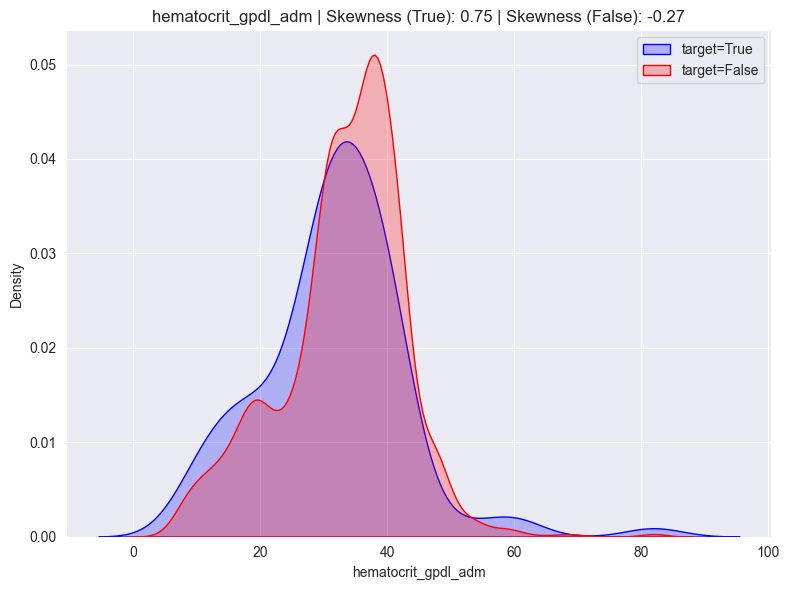

Point-Biserial Correlation: -0.033444285236476266 (p-value: 0.11444228577930181) - Not Statistically Significant
T-test Statistic: -1.3703800162741466 (p-value: 0.17346571803782246) - Not Statistically Significant
Odds Ratio (Logistic Regression): 0.9773866683653083 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.033444285236476266 (p-value: 0.11444228577930181) - Not Statistically Significant
momagefirstpreg_adm


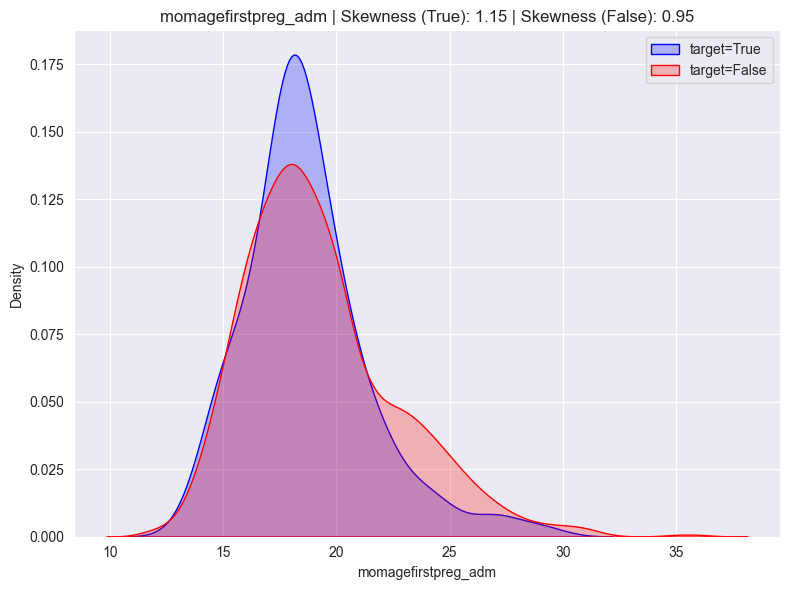

Point-Biserial Correlation: -0.03602045440107653 (p-value: 0.07394480093773521) - Not Statistically Significant
T-test Statistic: -2.199931996051216 (p-value: 0.02967989086421558) - Statistically Significant
Odds Ratio (Logistic Regression): 0.942513925956015 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.03602045440107653 (p-value: 0.07394480093773521) - Not Statistically Significant
alivechildren_adm


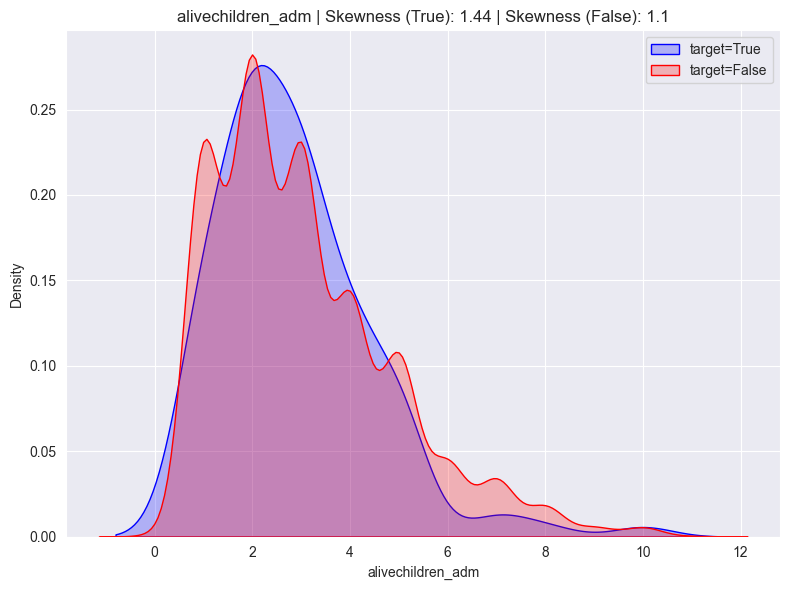

Point-Biserial Correlation: -0.02071537124296052 (p-value: 0.28352998522385653) - Not Statistically Significant
T-test Statistic: -1.2395464189146732 (p-value: 0.21731761065264224) - Not Statistically Significant
Odds Ratio (Logistic Regression): 0.912094107570305 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.02071537124296052 (p-value: 0.28352998522385653) - Not Statistically Significant


In [24]:
for f in ["hematocrit_gpdl_adm", "momagefirstpreg_adm", "alivechildren_adm"]:
    print(f)
    results = feature_inspection(f)

In [25]:
results

{'Point-Biserial Correlation': np.float64(-0.02071537124296052),
 'p-value (Point-Biserial)': np.float64(0.28352998522385653),
 'T-test Statistic': np.float64(-1.2395464189146732),
 'p-value (T-test)': np.float64(0.21731761065264224),
 'Odds Ratio (Logistic Regression)': np.float64(0.912094107570305),
 'p-value (Logistic Regression)': None,
 'Pearson Correlation': np.float64(-0.02071537124296052),
 'p-value (Pearson)': np.float64(0.28352998522385653)}

agecalc_adm


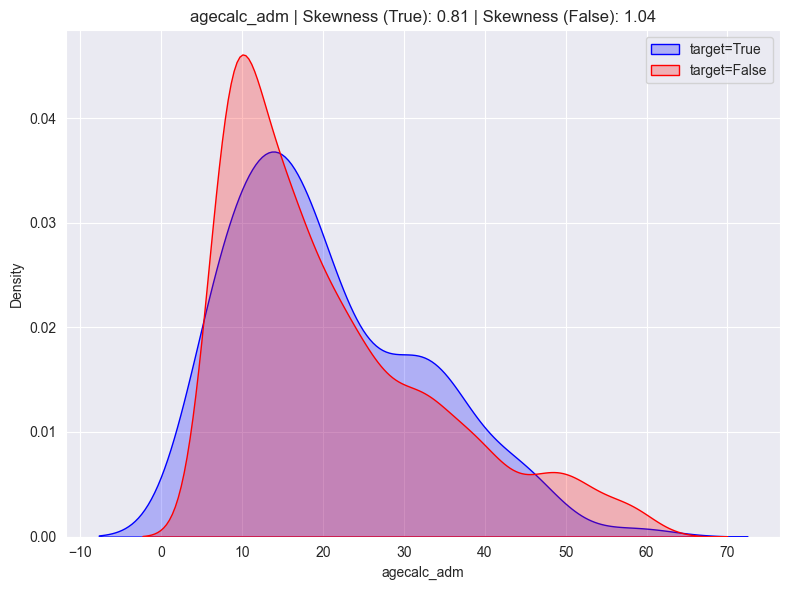

Point-Biserial Correlation: -0.00831315101347127 (p-value: 0.6667232216904414) - Not Statistically Significant
T-test Statistic: -0.47520434421612406 (p-value: 0.6354270194998034) - Not Statistically Significant
Odds Ratio (Logistic Regression): 0.9934559952184693 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.00831315101347127 (p-value: 0.6667232216904414) - Not Statistically Significant
height_cm_adm


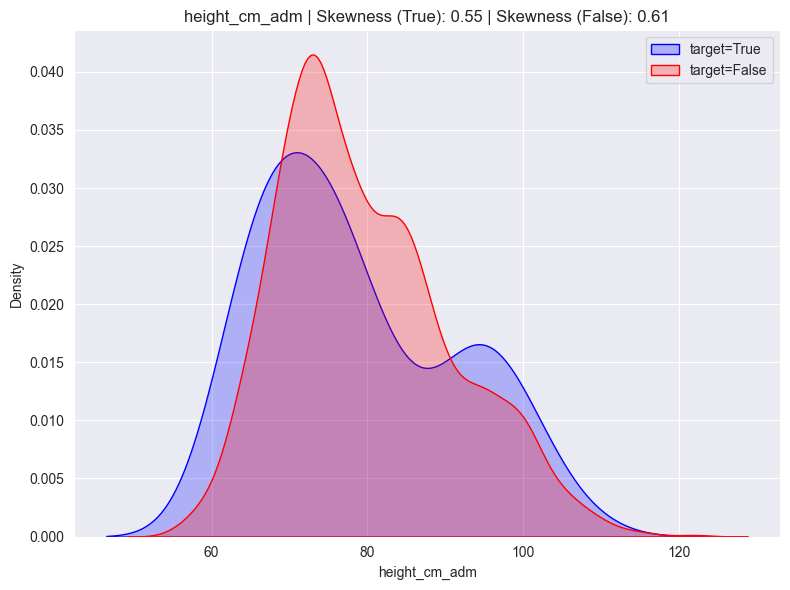

Point-Biserial Correlation: -0.01876909543742694 (p-value: 0.3321301789851805) - Not Statistically Significant
T-test Statistic: -0.8683969295194517 (p-value: 0.3869120172792191) - Not Statistically Significant
Odds Ratio (Logistic Regression): 0.9933226172149432 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.01876909543742694 (p-value: 0.3321301789851805) - Not Statistically Significant
weight_kg_adm


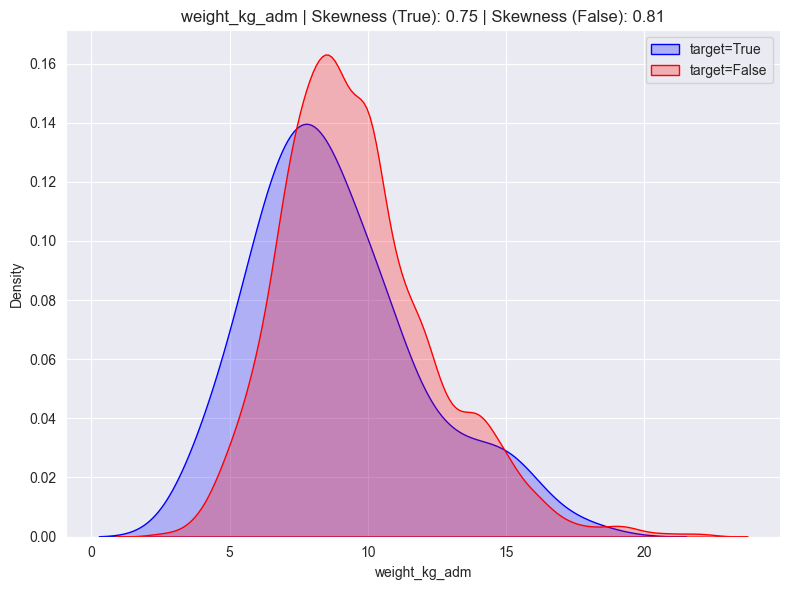

Point-Biserial Correlation: -0.053830153819157234 (p-value: 0.0053383133817236795) - Statistically Significant
T-test Statistic: -2.577737097907716 (p-value: 0.011115415030141943) - Statistically Significant
Odds Ratio (Logistic Regression): 0.9219834777719854 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.053830153819157234 (p-value: 0.0053383133817236795) - Statistically Significant
muac_mm_adm


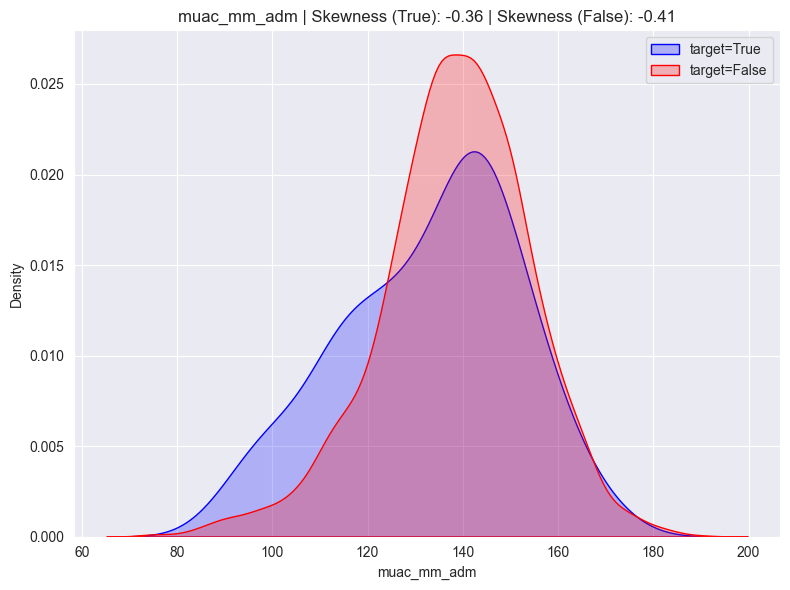

Point-Biserial Correlation: -0.0660269474543354 (p-value: 0.0006359623992254585) - Statistically Significant
T-test Statistic: -2.9387840436001267 (p-value: 0.003938283988197262) - Statistically Significant
Odds Ratio (Logistic Regression): 0.9843228687784816 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.0660269474543354 (p-value: 0.0006359623992254585) - Statistically Significant
hr_bpm_adm


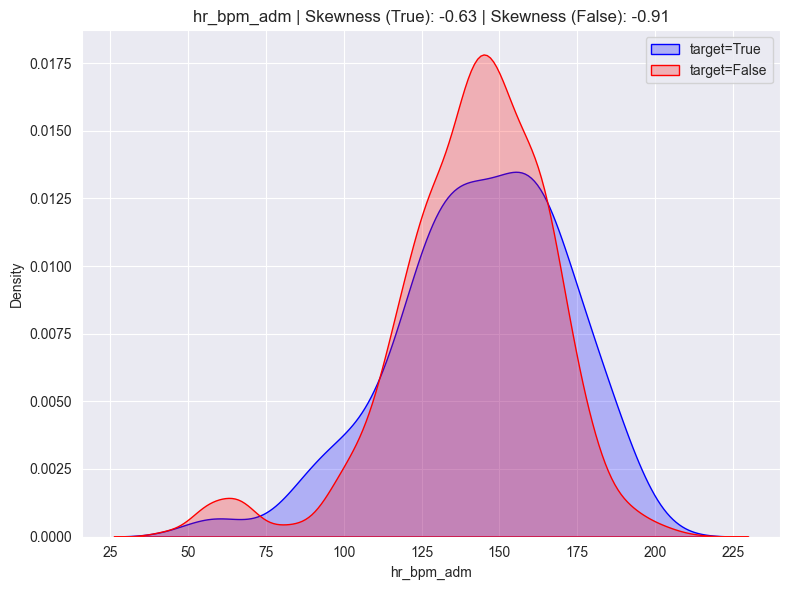

Point-Biserial Correlation: 0.020606989663056244 (p-value: 0.28578754423502833) - Not Statistically Significant
T-test Statistic: 1.0047659283855148 (p-value: 0.31690871017247985) - Not Statistically Significant
Odds Ratio (Logistic Regression): 1.0037990386885614 (p-value: None) - Not Statistically Significant
Pearson Correlation: 0.020606989663056244 (p-value: 0.28578754423502833) - Not Statistically Significant
rr_brpm_app_adm


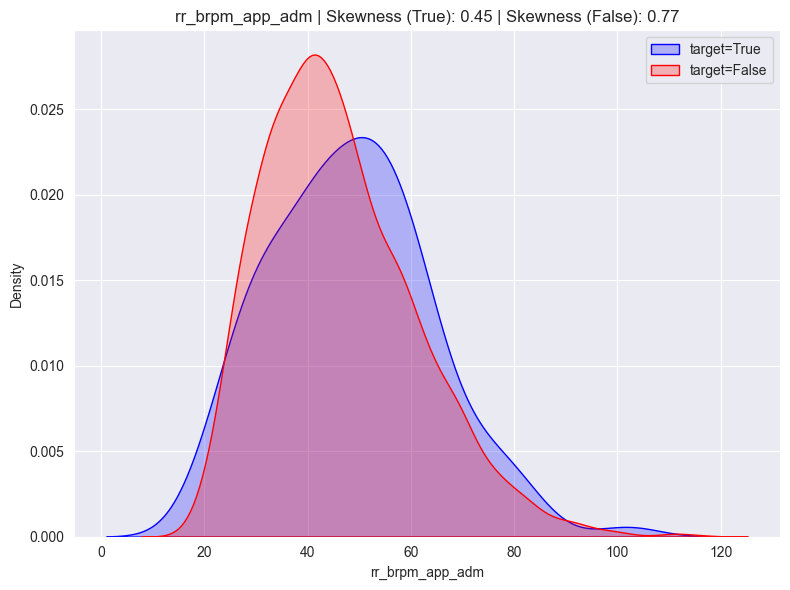

Point-Biserial Correlation: 0.03064622377743986 (p-value: 0.11263857165950591) - Not Statistically Significant
T-test Statistic: 1.514010332844086 (p-value: 0.13248700220496767) - Not Statistically Significant
Odds Ratio (Logistic Regression): 1.0068685077685682 (p-value: None) - Not Statistically Significant
Pearson Correlation: 0.03064622377743986 (p-value: 0.11263857165950591) - Not Statistically Significant
sysbp_mmhg_adm


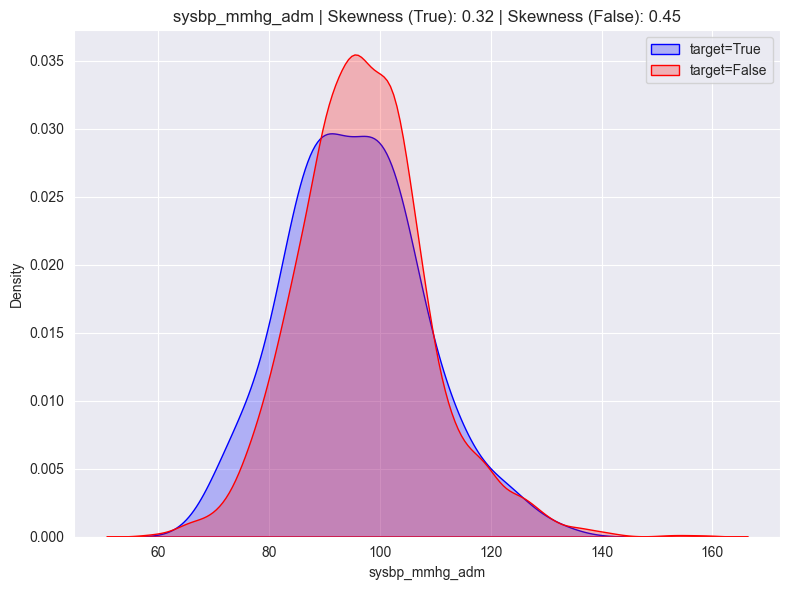

Point-Biserial Correlation: -0.028197943918742998 (p-value: 0.1441608845748287) - Not Statistically Significant
T-test Statistic: -1.4364919210236036 (p-value: 0.15328740671142593) - Not Statistically Significant
Odds Ratio (Logistic Regression): 0.9960148419101369 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.028197943918742998 (p-value: 0.1441608845748287) - Not Statistically Significant
diasbp_mmhg_adm


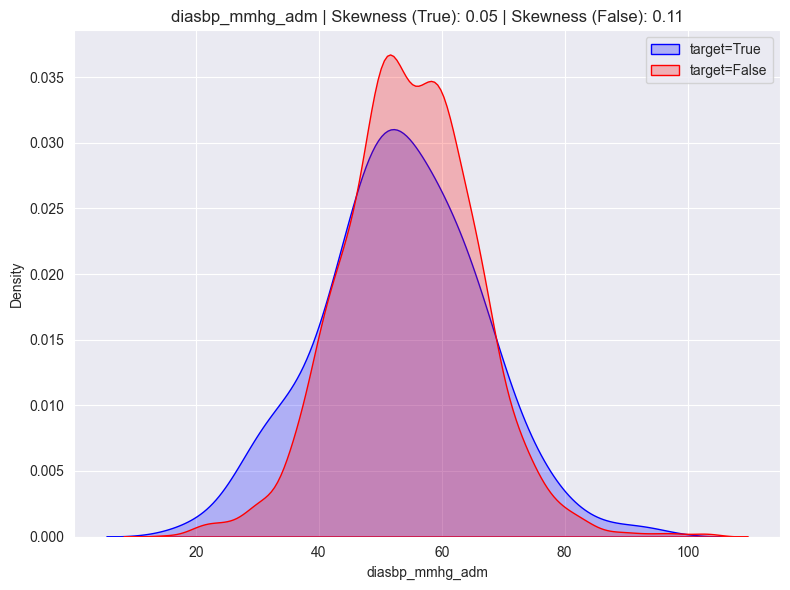

Point-Biserial Correlation: -0.027250646348949092 (p-value: 0.15805275680254416) - Not Statistically Significant
T-test Statistic: -1.2343801047166876 (p-value: 0.21935344202024537) - Not Statistically Significant
Odds Ratio (Logistic Regression): 1.0084382759051291 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.027250646348949092 (p-value: 0.15805275680254416) - Not Statistically Significant
temp_c_adm


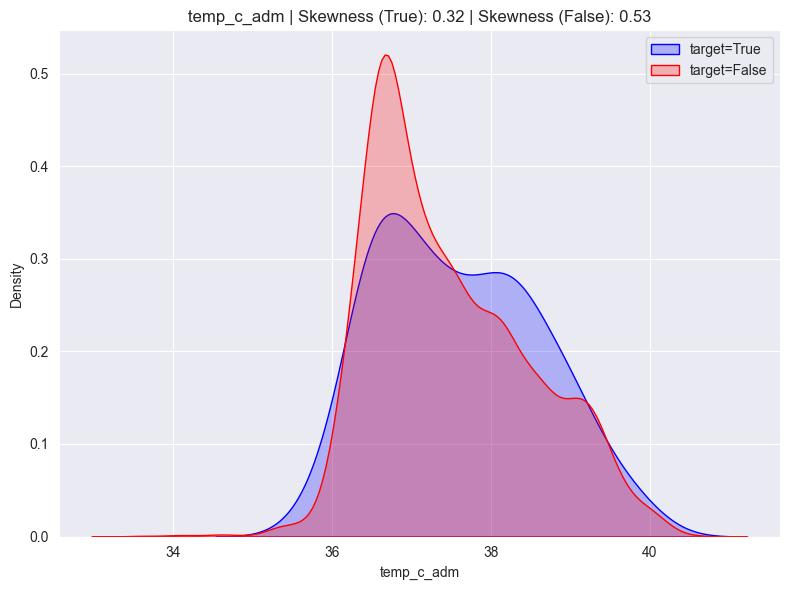

Point-Biserial Correlation: 0.02840042557986497 (p-value: 0.14122732304139363) - Not Statistically Significant
T-test Statistic: 1.470213826444822 (p-value: 0.14393568391460895) - Not Statistically Significant
Odds Ratio (Logistic Regression): 1.080203463853269 (p-value: None) - Not Statistically Significant
Pearson Correlation: 0.02840042557986497 (p-value: 0.14122732304139363) - Not Statistically Significant
spo2site1_pc_oxi_adm


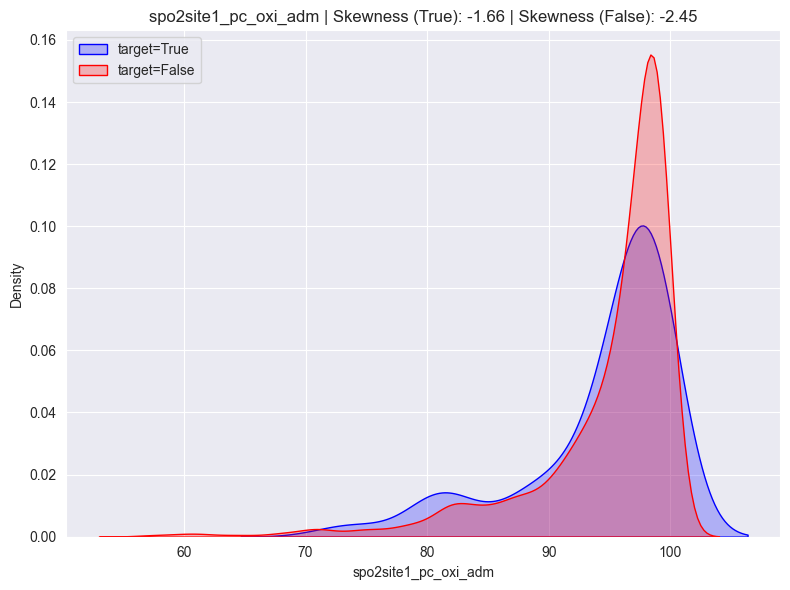

Point-Biserial Correlation: -0.017083525966628568 (p-value: 0.3764942192356148) - Not Statistically Significant
T-test Statistic: -0.8880453078301992 (p-value: 0.37616537620073587) - Not Statistically Significant
Odds Ratio (Logistic Regression): 0.9918139721679349 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.017083525966628568 (p-value: 0.3764942192356148) - Not Statistically Significant
spo2site2_pc_oxi_adm


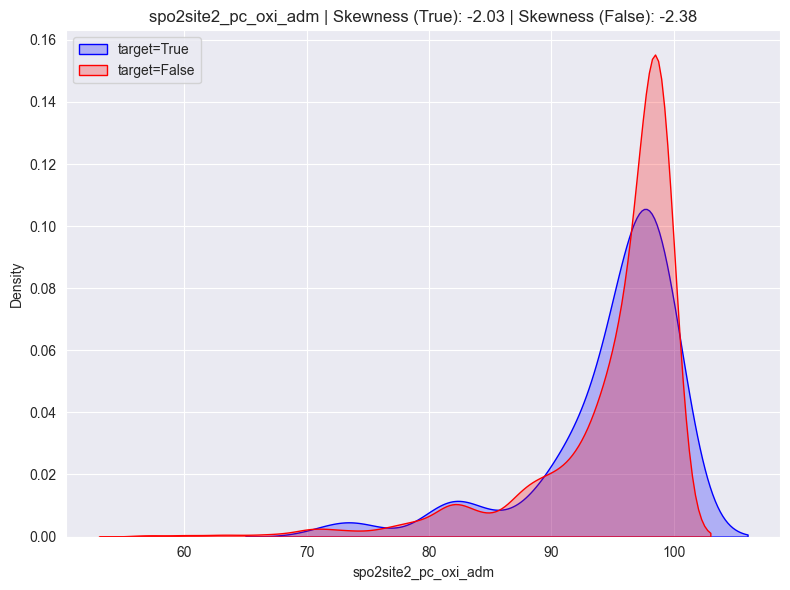

Point-Biserial Correlation: -0.0024760220061592142 (p-value: 0.9018950411598489) - Not Statistically Significant
T-test Statistic: -0.13042989047221298 (p-value: 0.8964598288915591) - Not Statistically Significant
Odds Ratio (Logistic Regression): 1.005418024523829 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.0024760220061592142 (p-value: 0.9018950411598489) - Not Statistically Significant
momage_adm


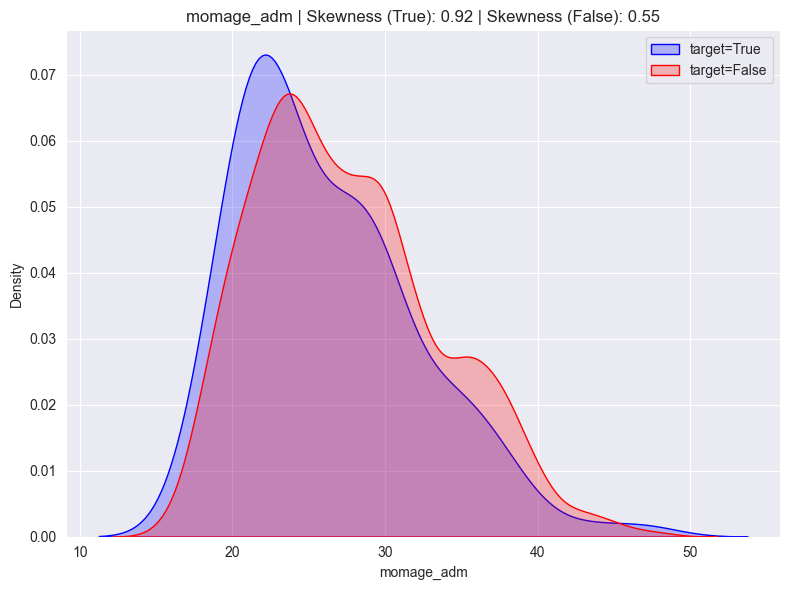

Point-Biserial Correlation: -0.04242627247951043 (p-value: 0.02845327121608116) - Statistically Significant
T-test Statistic: -2.2690818151795917 (p-value: 0.024924342676468376) - Statistically Significant
Odds Ratio (Logistic Regression): 0.9634840736064798 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.04242627247951043 (p-value: 0.02845327121608116) - Statistically Significant
momagefirstpreg_adm


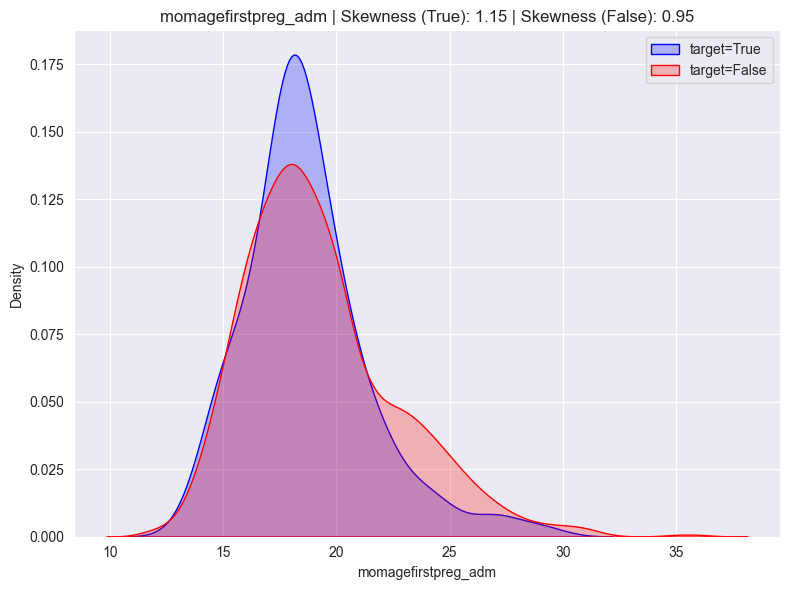

Point-Biserial Correlation: -0.03602045440107653 (p-value: 0.07394480093773521) - Not Statistically Significant
T-test Statistic: -2.199931996051216 (p-value: 0.02967989086421558) - Statistically Significant
Odds Ratio (Logistic Regression): 0.942513925956015 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.03602045440107653 (p-value: 0.07394480093773521) - Not Statistically Significant
householdsize_adm


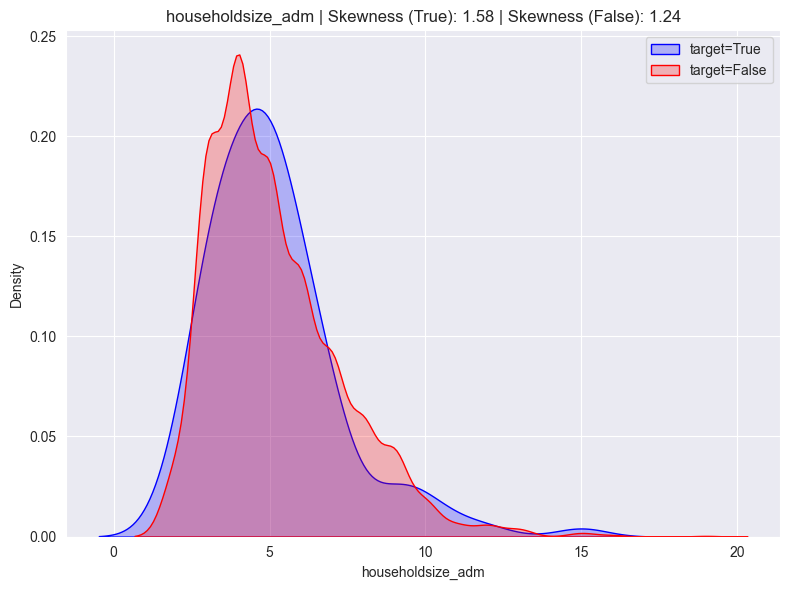

Point-Biserial Correlation: -0.003386230163906481 (p-value: 0.8608300476801329) - Not Statistically Significant
T-test Statistic: -0.1742601703764565 (p-value: 0.8619340940342857) - Not Statistically Significant
Odds Ratio (Logistic Regression): 0.9982308990880367 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.003386230163906481 (p-value: 0.8608300476801329) - Not Statistically Significant
alivechildren_adm


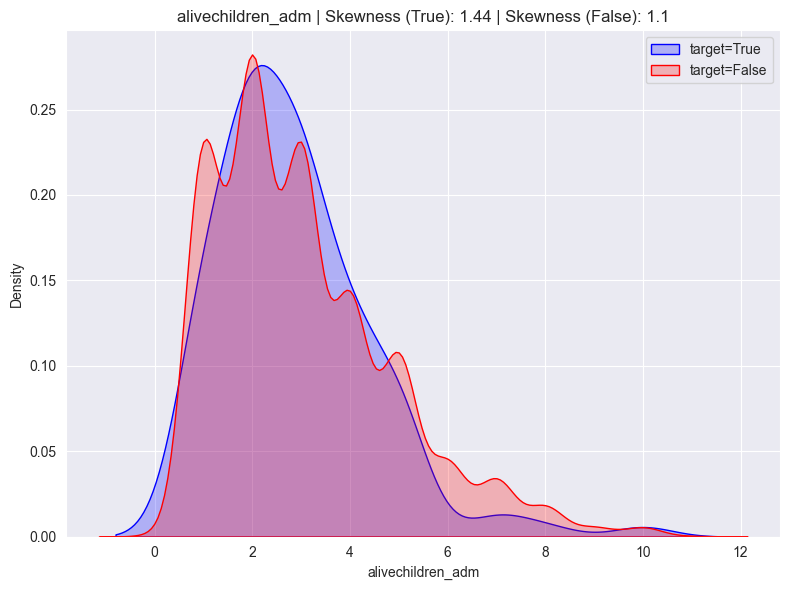

Point-Biserial Correlation: -0.02071537124296052 (p-value: 0.28352998522385653) - Not Statistically Significant
T-test Statistic: -1.2395464189146732 (p-value: 0.21731761065264224) - Not Statistically Significant
Odds Ratio (Logistic Regression): 0.912094107570305 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.02071537124296052 (p-value: 0.28352998522385653) - Not Statistically Significant
deadchildren_adm


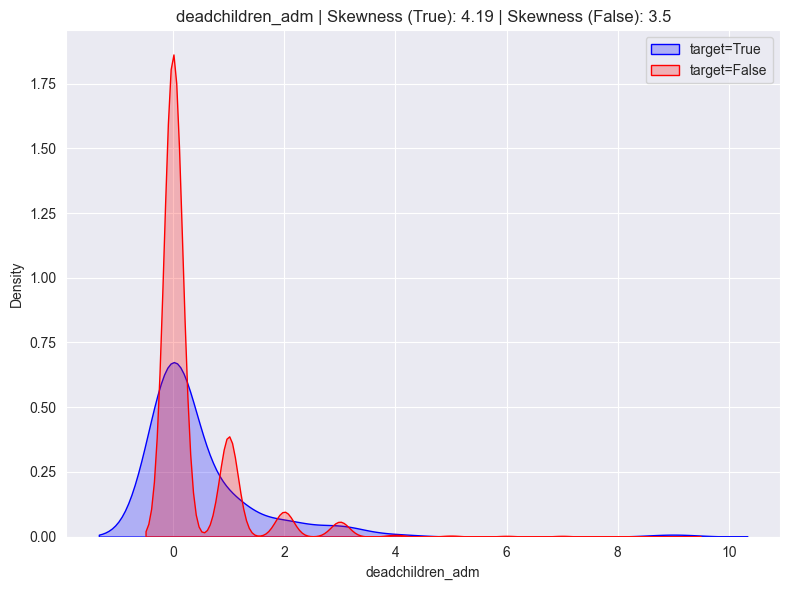

Point-Biserial Correlation: 0.03741747894641444 (p-value: 0.05254555557228272) - Not Statistically Significant
T-test Statistic: 1.3758053719491667 (p-value: 0.17137844765068352) - Not Statistically Significant
Odds Ratio (Logistic Regression): 1.1722030324341823 (p-value: None) - Not Statistically Significant
Pearson Correlation: 0.03741747894641444 (p-value: 0.05254555557228272) - Not Statistically Significant
glucose_mmolpl_adm


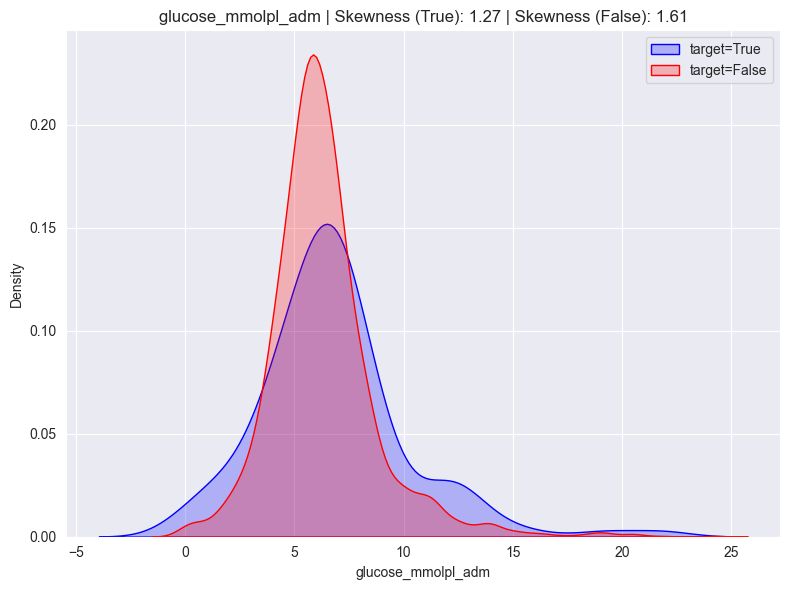

Point-Biserial Correlation: 0.040442860971886256 (p-value: 0.03640439535105865) - Statistically Significant
T-test Statistic: 1.5572149279394496 (p-value: 0.12199544972768743) - Not Statistically Significant
Odds Ratio (Logistic Regression): 1.0763648432471984 (p-value: None) - Not Statistically Significant
Pearson Correlation: 0.040442860971886256 (p-value: 0.03640439535105865) - Statistically Significant
sqi1_perc_oxi_adm


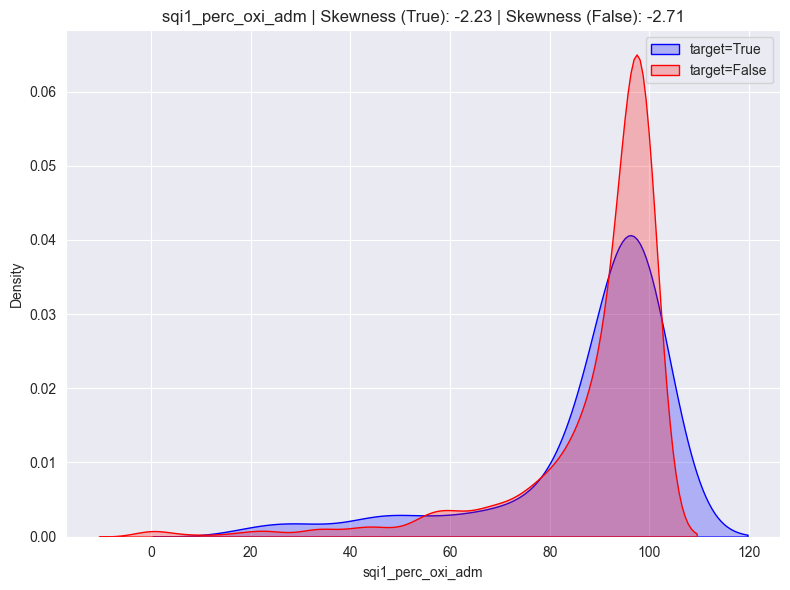

Point-Biserial Correlation: -0.008573142257796169 (p-value: 0.6648495534869776) - Not Statistically Significant
T-test Statistic: -0.4099528006449561 (p-value: 0.6825775379114798) - Not Statistically Significant
Odds Ratio (Logistic Regression): 0.9954104274950698 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.008573142257796169 (p-value: 0.6648495534869776) - Not Statistically Significant
sqi2_perc_oxi_adm


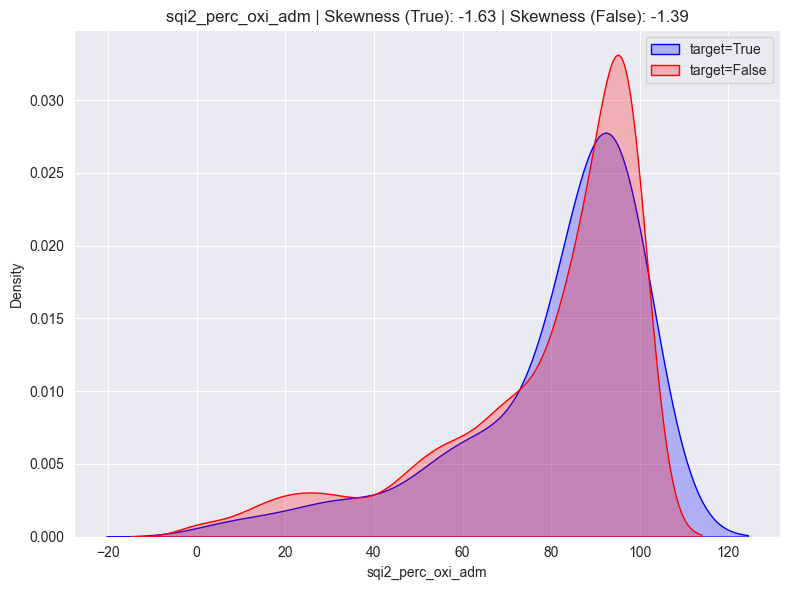

Point-Biserial Correlation: 0.021730828003518134 (p-value: 0.2794523916378021) - Not Statistically Significant
T-test Statistic: 1.1749567919935562 (p-value: 0.24245874406765883) - Not Statistically Significant
Odds Ratio (Logistic Regression): 1.0096722371158375 (p-value: None) - Not Statistically Significant
Pearson Correlation: 0.021730828003518134 (p-value: 0.2794523916378021) - Not Statistically Significant
lengthadm


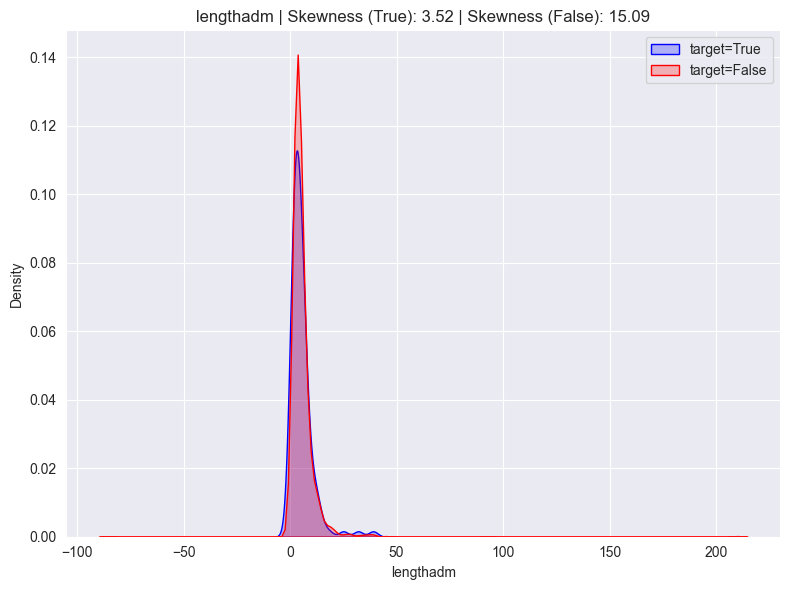

Point-Biserial Correlation: -0.004936297084794452 (p-value: 0.7981715781926975) - Not Statistically Significant
T-test Statistic: -0.34700046122933365 (p-value: 0.7291105975460315) - Not Statistically Significant
Odds Ratio (Logistic Regression): 0.9823978029675581 (p-value: None) - Not Statistically Significant
Pearson Correlation: -0.004936297084794452 (p-value: 0.7981715781926975) - Not Statistically Significant
inhospital_mortality


/var/folders/yj/c676wyw500q1vyq2brsvcqtr0000gn/T/ipykernel_31330/3909012764.py:30: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data_true[feature], color='blue', label='target=True', fill=True)
/var/folders/yj/c676wyw500q1vyq2brsvcqtr0000gn/T/ipykernel_31330/3909012764.py:33: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data_false[feature], color='red', label='target=False', fill=True)
/var/folders/yj/c676wyw500q1vyq2brsvcqtr0000gn/T/ipykernel_31330/3909012764.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


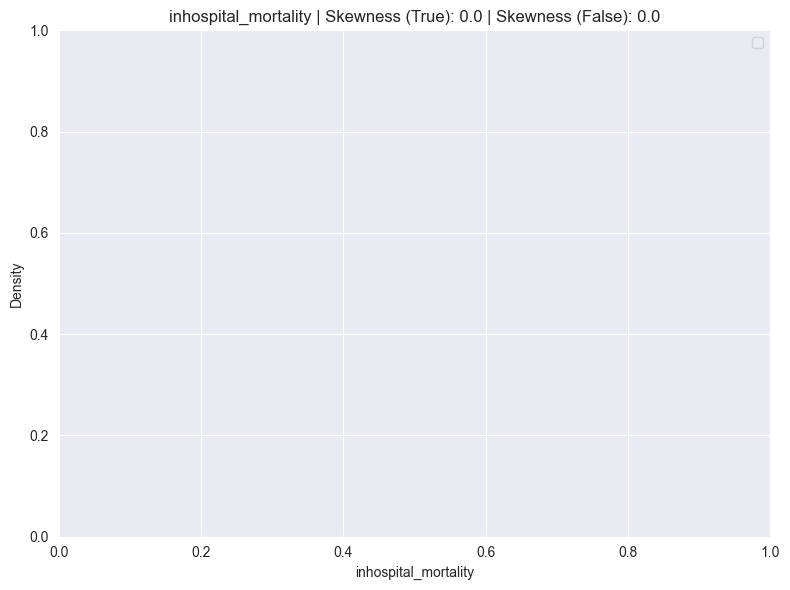

Could not inspect feature inhospital_mortality because of Error: y should be a 1d array, got an array of shape (1880, 2) instead.
Significant Numerical Features:
{'weight_kg_adm': ['Point-Biserial Correlation', 'T-test', 'Pearson Correlation'], 'muac_mm_adm': ['Point-Biserial Correlation', 'T-test', 'Pearson Correlation'], 'momage_adm': ['Point-Biserial Correlation', 'T-test', 'Pearson Correlation'], 'glucose_mmolpl_adm': ['Point-Biserial Correlation', 'Pearson Correlation']}


In [27]:
significant_numerical_features = {}

for f in numerical_columns: 
    print(f)
    try:
        results = feature_inspection(f)

        # Collect the tests that are statistically significant
        significant_tests = []

        # Check each test for statistical significance
        if results["p-value (Point-Biserial)"] < 0.05:
            significant_tests.append("Point-Biserial Correlation")
        if results["p-value (T-test)"] < 0.05:
            significant_tests.append("T-test")
        if results["p-value (Logistic Regression)"] is not None and results["p-value (Logistic Regression)"] < 0.05:
            significant_tests.append("Logistic Regression")
        if results["p-value (Pearson)"] < 0.05:
            significant_tests.append("Pearson Correlation")

        # If 2 or more tests are significant, add the feature to the dictionary
        if len(significant_tests) >= 2:
            significant_numerical_features[f] = significant_tests
    except Exception as e:
        print(f"Could not inspect feature {f} because of Error: {e}")

# Display significant numerical features
print("Significant Numerical Features:")
print(significant_numerical_features)


# Categorical Analysis

In [ ]:
# Identify categorical and binary columns
categorical_columns = data[features].select_dtypes(include=["object", "category"]).columns

# Identify binary columns (categorical with exactly two unique non-missing values)
binary_columns = [
    col for col in categorical_columns 
    if data[col].dropna().nunique() == 2  # Drop missing values before counting unique values
]

# Remove binary columns from categorical columns
categorical_columns = [col for col in categorical_columns if col not in binary_columns]



import pandas as pd
import numpy as np
from scipy.stats import fisher_exact, chi2_contingency
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

def binary_feature_tests(data, feature, target):
    """
    Run Fisher's Exact Test and Logistic Regression for binary features.

    Parameters:
    - data: DataFrame containing the data.
    - feature: The name of the feature (column) to check.
    - target: The name of the target column (binary values for True/False).
    
    Returns:
    - A dictionary with test results.
    """
    results = {}

    # Fisher's Exact Test
    crosstab = pd.crosstab(data[feature], data[target])
    _, p_value_fisher = fisher_exact(crosstab)
    results["Fisher's Exact Test p-value"] = p_value_fisher

    # Logistic Regression (with balanced class weights to handle unbalanced target)
    X = data[[feature]]
    y = data[target]
    
    # Split into training and testing sets (we'll fit the model on the training set)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    
    # Initialize logistic regression with balanced class weights
    model = LogisticRegression(class_weight='balanced', solver='liblinear')
    model.fit(X_train, y_train)
    
    # Model results
    odds_ratio = np.exp(model.coef_[0][0])  # exponentiated coefficient gives the odds ratio
    p_value_log_reg = model.pvalues_[0] if hasattr(model, 'pvalues_') else None
    
    results["Odds Ratio (Logistic Regression)"] = odds_ratio
    results["p-value (Logistic Regression)"] = p_value_log_reg
    
    return results

def categorical_feature_tests(data, feature, target):
    """
    Run Chi-Square Test and Cramér’s V for categorical features with more than two levels.

    Parameters:
    - data: DataFrame containing the data.
    - feature: The name of the feature (column) to check.
    - target: The name of the target column (binary values for True/False).
    
    Returns:
    - A dictionary with test results.
    """
    results = {}

    # Chi-Square Test
    crosstab = pd.crosstab(data[feature], data[target])
    chi2_stat, p_value_chi2, _, _ = chi2_contingency(crosstab)
    results["Chi-Square Test p-value"] = p_value_chi2
    
    # Cramér’s V
    n = crosstab.sum().sum()  # Total sample size
    min_dim = min(crosstab.shape) - 1
    cramers_v = np.sqrt(chi2_stat / (n * min_dim))
    results["Cramér’s V"] = cramers_v

    return results

def categorical_feature_inspection(data, feature, target):
    """
    Check the statistical significance of a categorical feature with respect to a binary target.

    Parameters:
    - data: DataFrame containing the data.
    - feature: The name of the feature (column) to check.
    - target: The name of the target column (binary values for True/False).
    
    Returns:
    - A dictionary with results for relevant tests (binary or categorical).
    """
    # Check if the feature is binary or categorical
    temp_data = data[feature].dropna()

    if temp_data.nunique() == 2:
        # If binary, run binary tests
        print(f"Running binary tests for {feature}")
        return binary_feature_tests(data, feature, target)
    else:
        # If categorical, run categorical tests
        print(f"Running categorical tests for {feature}")
        return categorical_feature_tests(data, feature, target)

# Example usage:
# Assuming `data` is your DataFrame, `feature_name` is the feature you're checking,
# and `target` is the binary target column.
results = categorical_feature_inspection(data, 'oxygenavail_adm', target)
print(results)

Running categorical tests for oxygenavail_adm
{'Chi-Square Test p-value': np.float64(2.852939553432146e-07), 'Cramér’s V': np.float64(0.11126029112553903)}


In [32]:
categorical_columns[0]

'oxygenavail_adm'

In [34]:
# Assuming significant_categorical_features will hold our final results
significant_categorical_features = {}

# Combine categorical and binary columns
all_categorical_columns = categorical_columns + binary_columns

# Loop through each feature (categorical + binary columns)
for f in all_categorical_columns: 
    print(f)
    try:
        print(f)
        filtered_data = data.dropna(subset=[f])
        results = categorical_feature_inspection(filtered_data, f, target)

        # Collect the tests that are statistically significant
        significant_tests = []

        # Check each test for statistical significance (use p-value thresholds)
        if "Fisher's Exact Test p-value" in results and results["Fisher's Exact Test p-value"] < 0.05:
            significant_tests.append("Fisher's Exact Test")
        
        if "Odds Ratio (Logistic Regression)" in results and results["p-value (Logistic Regression)"] is not None and results["p-value (Logistic Regression)"] < 0.05:
            significant_tests.append("Logistic Regression")
        
        if "Chi-Square Test p-value" in results and results["Chi-Square Test p-value"] < 0.05:
            significant_tests.append("Chi-Square Test")
        
        if "Cramér’s V" in results and results["Cramér’s V"] > 0.1:  # Threshold based on importance (Cramér’s V > 0.1 is typically considered a meaningful association)
            significant_tests.append("Cramér’s V")

        # If 2 or more tests are significant, add the feature to the dictionary
        if len(significant_tests) >= 1:
            significant_categorical_features[f] = significant_tests
    except Exception as e:
        print(f"Could not inspect feature {f} because of Error: {e}")

# Display significant categorical features
print("Significant Categorical Features:")
print(significant_categorical_features)


oxygenavail_adm
oxygenavail_adm
Running categorical tests for oxygenavail_adm
bcsmotor_adm
bcsmotor_adm
Running categorical tests for bcsmotor_adm
bcsverbal_adm
bcsverbal_adm
Running categorical tests for bcsverbal_adm
vaccmeasles_adm
vaccmeasles_adm
Running categorical tests for vaccmeasles_adm
vaccpneumoc_adm
vaccpneumoc_adm
Running categorical tests for vaccpneumoc_adm
vaccdpt_adm
vaccdpt_adm
Running categorical tests for vaccdpt_adm
priorweekabx_adm
priorweekabx_adm
Running categorical tests for priorweekabx_adm
priorweekantimal_adm
priorweekantimal_adm
Running categorical tests for priorweekantimal_adm
symptoms_adm___17
symptoms_adm___17
Running categorical tests for symptoms_adm___17
symptoms_adm___18
symptoms_adm___18
Running categorical tests for symptoms_adm___18
comorbidity_adm___4
comorbidity_adm___4
Running categorical tests for comorbidity_adm___4
priorhosp_adm
priorhosp_adm
Running categorical tests for priorhosp_adm
prioryearwheeze_adm
prioryearwheeze_adm
Running categor

/var/folders/yj/c676wyw500q1vyq2brsvcqtr0000gn/T/ipykernel_31330/2381017455.py:82: RuntimeWarning: invalid value encountered in divide
  cramers_v = np.sqrt(chi2_stat / (n * min_dim))
/var/folders/yj/c676wyw500q1vyq2brsvcqtr0000gn/T/ipykernel_31330/2381017455.py:82: RuntimeWarning: invalid value encountered in divide
  cramers_v = np.sqrt(chi2_stat / (n * min_dim))
/var/folders/yj/c676wyw500q1vyq2brsvcqtr0000gn/T/ipykernel_31330/2381017455.py:82: RuntimeWarning: invalid value encountered in divide
  cramers_v = np.sqrt(chi2_stat / (n * min_dim))
/var/folders/yj/c676wyw500q1vyq2brsvcqtr0000gn/T/ipykernel_31330/2381017455.py:82: RuntimeWarning: invalid value encountered in divide
  cramers_v = np.sqrt(chi2_stat / (n * min_dim))


Running categorical tests for badhealthduration_adm
caregiverage_adm
caregiverage_adm
Running categorical tests for caregiverage_adm
caregivermarried_adm
caregivermarried_adm
Running categorical tests for caregivermarried_adm
momedu_adm
momedu_adm
Running categorical tests for momedu_adm
momhiv_adm
momhiv_adm
Running categorical tests for momhiv_adm
watersource_adm
watersource_adm
Running categorical tests for watersource_adm
cookfuel_adm___8
cookfuel_adm___8
Running categorical tests for cookfuel_adm___8
cookloc_adm
cookloc_adm
Running categorical tests for cookloc_adm
lightfuel_adm
lightfuel_adm
Running categorical tests for lightfuel_adm
tobacco_adm
tobacco_adm
Running categorical tests for tobacco_adm
bednet_adm
bednet_adm
Running categorical tests for bednet_adm
caregiver_adm_new
caregiver_adm_new
Running categorical tests for caregiver_adm_new
sex_adm
sex_adm
Running binary tests for sex_adm
Could not inspect feature sex_adm because of Error: could not convert string to float: 'M

In [38]:
print(significant_categorical_features.keys())
print(significant_numerical_features.keys())

dict_keys(['oxygenavail_adm', 'bcsmotor_adm', 'bcsverbal_adm', 'vaccpneumoc_adm', 'vaccdpt_adm', 'priorhosp_adm', 'diarrheaoften_adm', 'feedingstatus_adm', 'exclbreastfed_adm', 'totalbreastfed_adm', 'caregivermarried_adm', 'tobacco_adm', 'bednet_adm'])
dict_keys(['weight_kg_adm', 'muac_mm_adm', 'momage_adm', 'glucose_mmolpl_adm'])


In [50]:
significant_columns = list(significant_numerical_features.keys()) + list(significant_categorical_features.keys())
significant_columns = significant_columns + ['inhospital_mortality']
# Filter the dataset to include only these columns
df = data[significant_columns].dropna()

for col in significant_columns:
    if df[col].isna().sum():
        print (col)

In [56]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score

# Split df into training and validation sets
X = df.drop(columns=[target])  # Assuming 'target' is the binary column you're predicting
y = df[target]

# Split into training and validation (80% train, 20% validation)
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

# Identify categorical and numerical columns
categorical_columns = X.select_dtypes(include=["object", "category"]).columns
numerical_columns = X.select_dtypes(include=["int64", "float64"]).columns

# Preprocessing steps:
# 1. For categorical features: Use OneHotEncoder
# 2. For numerical features: Use StandardScaler

# Define the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),  # Scale numerical features
        ('cat', OneHotEncoder(), categorical_columns)   # One-hot encode categorical features
    ])

# Create the logistic regression model
log_reg_model = LogisticRegression(class_weight='balanced', solver='liblinear')

# Create a pipeline that first preprocesses the data and then fits the logistic regression model
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', log_reg_model)
])

# Train the model
pipeline.fit(X_train, y_train)

# Predict on the validation set
y_pred = pipeline.predict(X_valid)

# Evaluate the model
print("Classification Report:\n", classification_report(y_valid, y_pred))
print("Accuracy Score:", accuracy_score(y_valid, y_pred))


Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.79      0.88       506
           1       0.10      0.60      0.17        20

    accuracy                           0.78       526
   macro avg       0.54      0.70      0.52       526
weighted avg       0.95      0.78      0.85       526

Accuracy Score: 0.7832699619771863


## Added sampling of the under-sized class with SMOTE

In [61]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score
from imblearn.over_sampling import SMOTE

# Split df into training and validation sets
X = df.drop(columns=[target])  # Assuming 'target' is the binary column you're predicting
y = df[target]

# Split into training and validation (80% train, 20% validation)
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

# Identify categorical and numerical columns
categorical_columns = X.select_dtypes(include=["object", "category"]).columns
numerical_columns = X.select_dtypes(include=["int64", "float64"]).columns

# Preprocessing steps:
# 1. For categorical features: Use OneHotEncoder
# 2. For numerical features: Use StandardScaler

# Define the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),  # Scale numerical features
        ('cat', OneHotEncoder(), categorical_columns)   # One-hot encode categorical features
    ])

# Create the logistic regression model
log_reg_model = LogisticRegression(class_weight='balanced', solver='liblinear')
svm_model = SVC(class_weight='balanced', kernel='linear', random_state=42)
# Create a pipeline that first preprocesses the data and then fits the logistic regression model
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', log_reg_model)
])

# Now, apply SMOTE after preprocessing, only on the training set
X_train_transformed = preprocessor.fit_transform(X_train)  # Apply the transformations to the training data
X_valid_transformed = preprocessor.transform(X_valid)      # Apply the same transformations to the validation data

# Initialize SMOTE for oversampling the minority class
smote = SMOTE(sampling_strategy='minority', random_state=42)

# Apply SMOTE to the transformed training data
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_transformed, y_train)

# Train the logistic regression model with the resampled data
# log_reg_model.fit(X_train_resampled, y_train_resampled)
svm_model.fit(X_train_resampled, y_train_resampled)
# Predict on the validation set
y_pred = svm_model.predict(X_valid_transformed)

# Evaluate the model
print("Classification Report:\n", classification_report(y_valid, y_pred))
print("Accuracy Score:", accuracy_score(y_valid, y_pred))


Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.73      0.84       506
           1       0.09      0.70      0.17        20

    accuracy                           0.73       526
   macro avg       0.54      0.72      0.50       526
weighted avg       0.95      0.73      0.81       526

Accuracy Score: 0.7319391634980988


In [62]:
log_reg_model = LogisticRegression(class_weight='balanced', solver='liblinear')
log_reg_model.fit(X_train_resampled, y_train_resampled)
y_pred = log_reg_model.predict(X_valid_transformed)

# Evaluate the model
print("Classification Report:\n", classification_report(y_valid, y_pred))
print("Accuracy Score:", accuracy_score(y_valid, y_pred))

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.75      0.85       506
           1       0.09      0.65      0.17        20

    accuracy                           0.75       526
   macro avg       0.54      0.70      0.51       526
weighted avg       0.95      0.75      0.83       526

Accuracy Score: 0.7509505703422054


In [59]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score
from imblearn.over_sampling import SMOTE

# Split df into training and validation sets
X = df.drop(columns=[target])  # Assuming 'target' is the binary column you're predicting
y = df[target]

# Split into training and validation (80% train, 20% validation)
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

# Identify categorical and numerical columns
categorical_columns = X.select_dtypes(include=["object", "category"]).columns
numerical_columns = X.select_dtypes(include=["int64", "float64"]).columns

# Preprocessing steps:
# 1. For categorical features: Use OneHotEncoder
# 2. For numerical features: Use StandardScaler

# Define the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),  # Scale numerical features
        ('cat', OneHotEncoder(), categorical_columns)   # One-hot encode categorical features
    ])

# Initialize SMOTE for oversampling the minority class
smote = SMOTE(sampling_strategy='minority', random_state=42)

# Create the SVM model with class weights
svm_model = SVC(class_weight='balanced', kernel='linear', random_state=42)

# Create a pipeline that first preprocesses the data, applies SMOTE, and then fits the SVM model
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', smote),  # Apply SMOTE to oversample the minority class
    ('classifier', svm_model)
])

# Train the model
pipeline.fit(X_train, y_train)

# Predict on the validation set
y_pred = pipeline.predict(X_valid)

# Evaluate the model
print("Classification Report:\n", classification_report(y_valid, y_pred))
print("Accuracy Score:", accuracy_score(y_valid, y_pred))


TypeError: All intermediate steps should be transformers and implement fit and transform or be the string 'passthrough' 'SMOTE(random_state=42, sampling_strategy='minority')' (type <class 'imblearn.over_sampling._smote.base.SMOTE'>) doesn't

# Missing Values 
## Height & Weight. Using KNN.

## Strategy
* Isolate/filter dataset for only age, height, weight and target columns
* Use KNNImputer and Scaling to fill missing values.
* Visualize pre and post alteration - histogram of individual features and PCA
* Create a pipeline for this process.

In [103]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
data = pd.read_csv("../SyntheticData_Training.csv")
data = data.iloc[:, 1:] # remove id column
target = data.columns[-1] # save target column

height: height_cm_adm
weight: weight_kg_adm
age: agecalc_adm

In [116]:
# Visualizing pre-handling missing values

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

# Example dataset
df = data[["agecalc_adm", "weight_kg_adm", "height_cm_adm", target]]

# Features
features = df[["agecalc_adm", "weight_kg_adm", "height_cm_adm"]]

# Step 1: Impute missing values using KNN
imputer = KNNImputer(n_neighbors=3)
features_imputed = imputer.fit_transform(features)
df_imputed = df.copy()
df_imputed[["agecalc_adm", "weight_kg_adm", "height_cm_adm"]] = features_imputed

# Step 2: Cluster the imputed data
scaler = StandardScaler()
features_scaled = scaler.fit_transform(df_imputed)
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(features_scaled)
df_imputed['cluster'] = clusters

In [118]:
# Step 6: Add a "filled" column to indicate which values were filled
df["filled"] = 0  # Original data column
df_imputed["filled"] = 0
missing_mask = df[["weight_kg_adm", "height_cm_adm"]].isna()
# Update the "filled" column for imputed data
for col in ["weight_kg_adm", "height_cm_adm"]:
    df_imputed.loc[missing_mask[col], "filled"] = 1

# Display original and imputed DataFrames
df_ = df.dropna().copy().reset_index(drop=True)


print("Original DataFrame:")
display(df_)

print("\nImputed DataFrame:")
display(df_imputed)

Original DataFrame:


/var/folders/yj/c676wyw500q1vyq2brsvcqtr0000gn/T/ipykernel_31330/3885614721.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["filled"] = 0  # Original data column


,agecalc_adm,weight_kg_adm,height_cm_adm,inhospital_mortality,filled
0,16.8,11.6,79.8,0,0
1,46.1,13.6,93.0,0,0
2,7.9,8.2,68.2,0,0
3,38.2,12.0,95.0,0,0
4,16.1,12.0,83.0,0,0
...,...,...,...,...,...
2666,20.1,10.0,98.2,0,0
2667,26.8,10.0,82.3,0,0
2668,14.6,12.7,82.4,0,0
2669,9.5,7.5,67.5,0,0



Imputed DataFrame:


,agecalc_adm,weight_kg_adm,height_cm_adm,inhospital_mortality,cluster,filled
0,16.8,11.6,79.8,0,0,0
1,46.1,13.6,93.0,0,1,0
2,7.9,8.2,68.2,0,2,0
3,38.2,12.0,95.0,0,1,0
4,16.1,12.0,83.0,0,0,0
...,...,...,...,...,...,...
2681,20.1,10.0,98.2,0,0,0
2682,26.8,10.0,82.3,0,0,0
2683,14.6,12.7,82.4,0,0,0
2684,9.5,7.5,67.5,0,2,0


In [110]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler


# Step 1: Create a mask for missing values
missing_mask = df[["weight_kg_adm", "height_cm_adm"]].isna()

# Step 2: Scale the features using MinMaxScaler
scaler = MinMaxScaler()
scaled_features = scaler.fit_transform(df[["agecalc_adm", "weight_kg_adm", "height_cm_adm"]])

# Step 3: Apply KNNImputer
imputer = KNNImputer(n_neighbors=3)
scaled_imputed = imputer.fit_transform(scaled_features)

# Step 4: Inverse scale the imputed data back to the original scale
imputed_features = scaler.inverse_transform(scaled_imputed)

# Step 5: Add the imputed data back into the DataFrame
df_imputed = df.copy()
df_imputed[["agecalc_adm", "weight_kg_adm", "height_cm_adm"]] = imputed_features

# Step 6: Add a "filled" column to indicate which values were filled
df["filled"] = 0  # Original data column
df_imputed["filled"] = 0

# Update the "filled" column for imputed data
for col in ["weight_kg_adm", "height_cm_adm"]:
    df_imputed.loc[missing_mask[col], "filled"] = 1

# Display original and imputed DataFrames
df_ = df.dropna().copy().reset_index(drop=True)


print("Original DataFrame:")
display(df_)

print("\nImputed DataFrame:")
display(df_imputed)



Original DataFrame:


/var/folders/yj/c676wyw500q1vyq2brsvcqtr0000gn/T/ipykernel_31330/54427149.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["filled"] = 0  # Original data column


,agecalc_adm,weight_kg_adm,height_cm_adm,inhospital_mortality,filled
0,16.8,11.6,79.8,0,0
1,46.1,13.6,93.0,0,0
2,7.9,8.2,68.2,0,0
3,38.2,12.0,95.0,0,0
4,16.1,12.0,83.0,0,0
...,...,...,...,...,...
2666,20.1,10.0,98.2,0,0
2667,26.8,10.0,82.3,0,0
2668,14.6,12.7,82.4,0,0
2669,9.5,7.5,67.5,0,0



Imputed DataFrame:


,agecalc_adm,weight_kg_adm,height_cm_adm,inhospital_mortality,filled
0,16.8,11.6,79.8,0,0
1,46.1,13.6,93.0,0,0
2,7.9,8.2,68.2,0,0
3,38.2,12.0,95.0,0,0
4,16.1,12.0,83.0,0,0
...,...,...,...,...,...
2681,20.1,10.0,98.2,0,0
2682,26.8,10.0,82.3,0,0
2683,14.6,12.7,82.4,0,0
2684,9.5,7.5,67.5,0,0


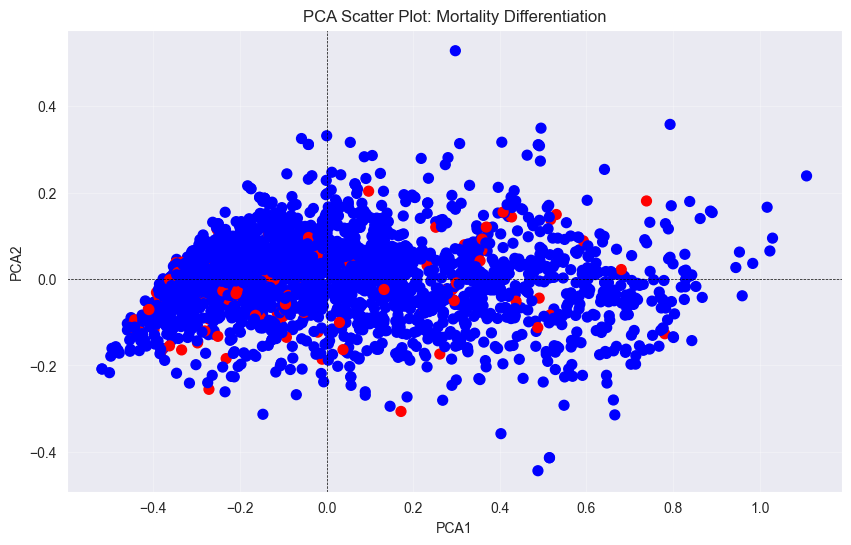

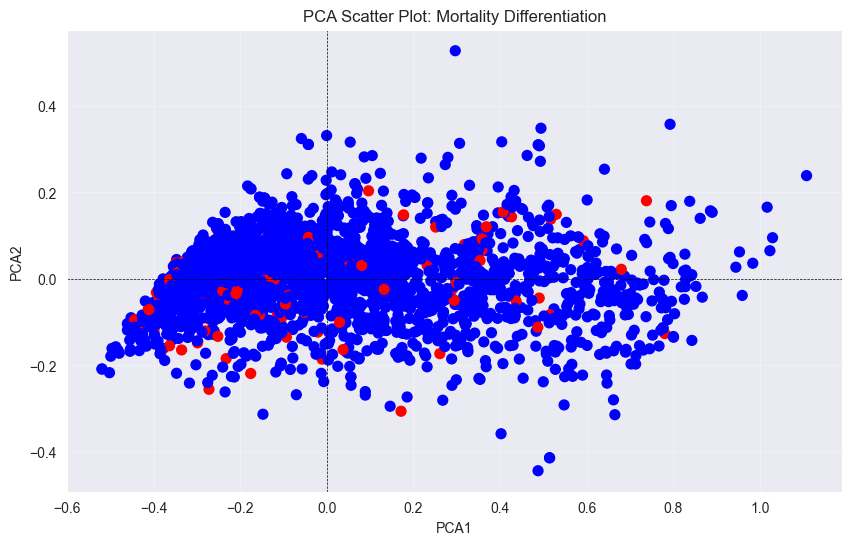

In [119]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pltMinMaxScaler
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler

# Example dataset

for df in [df_, df_imputed]:

    # Step 1: Standardize the features
    features = df[["agecalc_adm", "weight_kg_adm", "height_cm_adm"]]
    scaler = MinMaxScaler()
    features_scaled = scaler.fit_transform(features)

    # Step 2: Apply PCA to reduce dimensions to 2
    pca = PCA(n_components=2)
    pca_components = pca.fit_transform(features_scaled)

    # Step 3: Create a DataFrame for the PCA results
    pca_df = pd.DataFrame(pca_components, columns=["PCA1", "PCA2"])
    pca_df[target] = df[target]

    # Step 4: Plot the PCA results with color differentiation by mortality
    def plot_pca_scatter(data, x_col, y_col, target_col, title):
        plt.figure(figsize=(10, 6))
        colors = data[target_col].map({0: 'blue', 1: 'red'})  # Blue for 0, Red for 1
        plt.scatter(data[x_col], data[y_col], c=colors, s=50)
        plt.xlabel(x_col)
        plt.ylabel(y_col)
        plt.title(title)
        plt.axhline(0, color="black", linewidth=0.5, linestyle="--")
        plt.axvline(0, color="black", linewidth=0.5, linestyle="--")
        plt.grid(alpha=0.3)
        plt.show()

    # Visualize the PCA scatter plot
    plot_pca_scatter(pca_df, "PCA1", "PCA2", target, "PCA Scatter Plot: Mortality Differentiation")


In [121]:
df_imputed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2686 entries, 0 to 2685
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   agecalc_adm           2686 non-null   float64
 1   weight_kg_adm         2686 non-null   float64
 2   height_cm_adm         2686 non-null   float64
 3   inhospital_mortality  2686 non-null   int64  
 4   cluster               2686 non-null   int32  
 5   filled                2686 non-null   int64  
dtypes: float64(3), int32(1), int64(2)
memory usage: 115.5 KB
